EDA warstwy Silver (`games_silver.parquet`)

Zakres: eksploracyjna analiza danych zbioru Silver (58 kolumn) pod kątem
szukania nisz na Steam i późniejszego modelowania ML.

## 1. Konfiguracja i wczytanie danych

In [2]:
import os, warnings
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 13, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# --- parametry analizy (do dowolnej zmiany) ---
MIN_N_GENRE = 30      # min. liczba gier, by gatunek trafił do analizy nisz
MIN_N_PAIR = 100      # min. liczba gier, by para gatunków trafiła do analizy nisz
EXCLUDE_GENRES = {"Early Access", "Free To Play"}   # etykiety stanu/monetyzacji, nie treści gry
RANDOM_STATE = 42

In [3]:
PATH = "games_silver.parquet"          # w Colabie katalog roboczy to /content
if not os.path.exists(PATH):
    from google.colab import files     # ręczne wgranie pliku
    uploaded = files.upload()
    PATH = next(iter(uploaded))

df = pd.read_parquet(PATH)
N_ORIG_COLS = df.shape[1]
print(f"Wczytano: {PATH}  ->  {df.shape[0]:,} wierszy x {df.shape[1]} kolumn")

Wczytano: games_silver.parquet  ->  22,655 wierszy x 58 kolumn


In [4]:
# ---------- grupy kolumn wg słownika ----------
BOOL_FLAGS = ["is_free", "is_delisted_or_bundled", "has_metacritic", "windows", "mac", "linux",
              "is_indie", "is_early_access", "is_singleplayer", "is_multiplayer", "is_coop", "is_pvp",
              "has_controller_support", "has_steam_workshop", "is_vr_supported", "is_self_published"]
TARGET_BOOL = ["target_is_commercial_hit", "target_is_hidden_gem", "target_is_evergreen"]
TARGET_NUM = ["target_log_revenue_per_day", "target_unmet_demand_score"]
TARGETS = TARGET_NUM + TARGET_BOOL
LIST_COLS = ["genres_list", "categories_list"]
BOOL_COLS = [c for c in BOOL_FLAGS + TARGET_BOOL if c in df.columns]

# ---------- przygotowanie typów ----------
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")
for c in LIST_COLS:   # VARCHAR[] -> zwykłe listy pythonowe
    df[c] = df[c].apply(lambda v: list(v) if isinstance(v, (list, tuple, np.ndarray)) else [])
for c in BOOL_COLS:   # nullable boolean (obsługuje NA, np. is_self_published)
    df[c] = df[c].astype("boolean")

NUM_COLS = [c for c in df.select_dtypes("number").columns if c != "app_id" and c not in BOOL_COLS]
NUM_FEATURES = [c for c in NUM_COLS if c not in TARGETS]

# ---------- kolumny pomocnicze (tylko do EDA) ----------
df["revenue_per_day"] = df["estimated_revenue_usd"] / df["game_age_days"]
for c in TARGET_BOOL:
    df[c.replace("target_is_", "") + "_f"] = df[c].astype(float)     # hit_f -> commercial_hit_f itd.
df["price_band"] = pd.cut(df["price_initial_usd"].where(~df["is_free"].fillna(False).astype(bool)),
                          bins=[0, 0.99, 4.99, 9.99, 14.99, 19.99, 29.99, 59.99, np.inf],
                          labels=["<1", "1-5", "5-10", "10-15", "15-20", "20-30", "30-60", "60+"])
df["volume_band"] = pd.cut(df["total_reviews"], bins=[0, 9, 49, 99, 499, 999, 9999, np.inf],
                           labels=["1-9", "10-49", "50-99", "100-499", "500-999", "1k-10k", "10k+"])
print("Kolumn numerycznych:", len(NUM_COLS), "| binarnych:", len(BOOL_COLS), "| list:", len(LIST_COLS))

Kolumn numerycznych: 28 | binarnych: 19 | list: 2


## 2. Przegląd struktury

In [5]:
print(f"Wiersze: {len(df):,} | Kolumny: {df.shape[1]} | Pamięć: {df.memory_usage(deep=True).sum()/1e6:,.1f} MB")
schema = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(2),
})
schema["n_unique"] = [df[c].nunique() if c not in LIST_COLS else np.nan for c in df.columns]
display(schema)

Wiersze: 22,655 | Kolumny: 64 | Pamięć: 29.2 MB


,dtype,n_missing,pct_missing,n_unique
app_id,int32,0,0.000,"22,655.000"
name,object,0,0.000,"22,606.000"
is_free,boolean,0,0.000,2.000
is_delisted_or_bundled,boolean,0,0.000,2.000
release_date,datetime64[ns],66,0.290,"4,606.000"
price_initial_usd,float64,1156,5.100,147.000
price_final_usd,float64,1156,5.100,330.000
discount_percent,int32,0,0.000,71.000
positive_reviews,int32,0,0.000,"5,620.000"
negative_reviews,int32,0,0.000,"2,804.000"


In [6]:
display(df.drop(columns=["price_band", "volume_band"]).head(5).T)

,0,1,2,3,4
app_id,10,20,30,40,50
name,Counter-Strike,Team Fortress Classic,Day of Defeat,Deathmatch Classic,Half-Life: Opposing Force
is_free,False,False,False,False,False
is_delisted_or_bundled,False,False,False,False,False
release_date,2000-11-01 00:00:00,1999-04-01 00:00:00,2003-05-01 00:00:00,2001-06-01 00:00:00,1999-11-01 00:00:00
price_initial_usd,9.990,4.990,4.990,4.990,4.990
price_final_usd,9.990,4.990,4.990,4.990,4.990
discount_percent,0,0,0,0,0
positive_reviews,243818,7602,6414,2618,24363
negative_reviews,6427,1136,688,545,1198


## 3. Jakość danych

### 3.1 Braki danych

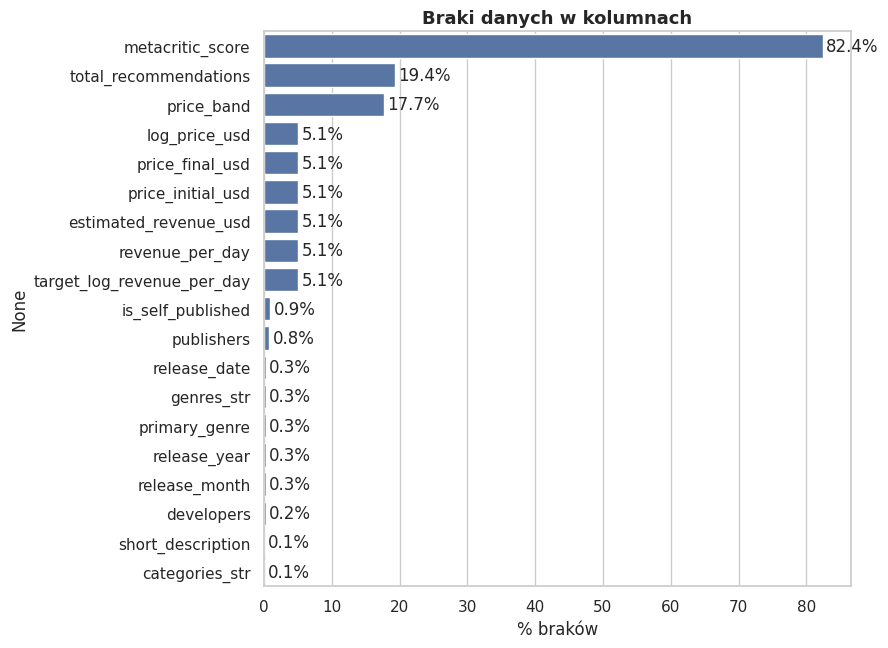

In [7]:
miss = schema[schema.n_missing > 0].sort_values("pct_missing", ascending=False)
fig, ax = plt.subplots(figsize=(9, max(3, 0.35 * len(miss))))
sns.barplot(x=miss.pct_missing, y=miss.index, color="#4C72B0", ax=ax)
for i, v in enumerate(miss.pct_missing):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center")
ax.set_xlabel("% braków"); ax.set_title("Braki danych w kolumnach")
plt.tight_layout(); plt.show()

In [8]:
# Które braki są strukturalne (wynikają z definicji potoku), a które losowe?
print("Brak ceny vs is_delisted_or_bundled:")
display(pd.crosstab(df["price_initial_usd"].isna().rename("price_NaN"), df["is_delisted_or_bundled"]))
print("Brak metacritic_score vs has_metacritic:")
display(pd.crosstab(df["metacritic_score"].isna().rename("score_NaN"), df["has_metacritic"]))
print(f"estimated_revenue_usd = NaN: {df.estimated_revenue_usd.isna().sum():,} | "
      f"w tym przy braku ceny: {(df.estimated_revenue_usd.isna() & df.price_initial_usd.isna()).sum():,}")

Brak ceny vs is_delisted_or_bundled:


is_delisted_or_bundled,False,True
price_NaN,,
False,21499,0
True,0,1156


Brak metacritic_score vs has_metacritic:


has_metacritic,False,True
score_NaN,,
False,0,3988
True,18667,0


estimated_revenue_usd = NaN: 1,156 | w tym przy braku ceny: 1,156


### 3.2 Spójność logiczna

In [9]:
B = lambda c: df[c].fillna(False).astype(bool)
checks = {
    "duplikaty app_id": df.app_id.duplicated().sum(),
    "total_reviews != positive + negative": (df.total_reviews != df.positive_reviews + df.negative_reviews).sum(),
    "total_reviews <= 0": (df.total_reviews <= 0).sum(),
    "positive_ratio poza [0, 1]": ((df.positive_ratio < 0) | (df.positive_ratio > 1)).sum(),
    "wilson_score poza [0, 1]": ((df.wilson_score < 0) | (df.wilson_score > 1)).sum(),
    "wilson_score > positive_ratio": (df.wilson_score > df.positive_ratio + 1e-6).sum(),
    "owners_min > owners_max": (df.owners_min > df.owners_max).sum(),
    "ceny ujemne": ((df.price_initial_usd < 0) | (df.price_final_usd < 0)).sum(),
    "price_final > price_initial": (df.price_final_usd > df.price_initial_usd).sum(),
    "is_free, ale cena > 0": (B("is_free") & (df.price_initial_usd > 0)).sum(),
    "game_age_days < 1": (df.game_age_days < 1).sum(),
    "release_date w przyszłości": (df.release_date > pd.Timestamp.today()).sum(),
    "release_date < 1997": (df.release_date < "1997-01-01").sum(),
    "metacritic poza [0, 100]": ((df.metacritic_score < 0) | (df.metacritic_score > 100)).sum(),
    "has_metacritic != (score nie-NaN)": (B("has_metacritic") != df.metacritic_score.notna()).sum(),
    "platforms_count != windows+mac+linux": (df.platforms_count != df[["windows", "mac", "linux"]].astype(float).sum(axis=1)).sum(),
    "gry bez żadnej platformy (platforms_count = 0)": (df.platforms_count == 0).sum(),
    "ccu > owners_max": (df.ccu > df.owners_max).sum(),
}
chk = pd.Series(checks, name="n_naruszeń").to_frame()
chk["% wierszy"] = (chk.n_naruszeń / len(df) * 100).round(3)
display(chk.style.background_gradient(subset=["n_naruszeń"], cmap="Reds"))

,n_naruszeń,% wierszy
duplikaty app_id,0,0.000000
total_reviews != positive + negative,0,0.000000
total_reviews <= 0,0,0.000000
"positive_ratio poza [0, 1]",0,0.000000
"wilson_score poza [0, 1]",0,0.000000
wilson_score > positive_ratio,0,0.000000
owners_min > owners_max,0,0.000000
ceny ujemne,0,0.000000
price_final > price_initial,0,0.000000
"is_free, ale cena > 0",0,0.000000


### 3.3 Walidacja definicji ze słownika (przeliczenie zmiennych pochodnych)

In [10]:
def wilson_lb(pos, n, z=1.96):
    p = pos / n
    return (p + z**2 / (2 * n) - z * np.sqrt((p * (1 - p) + z**2 / (4 * n)) / n)) / (1 + z**2 / n)

val = {}
val["wilson_score (max |różnica|)"] = (wilson_lb(df.positive_reviews, df.total_reviews) - df.wilson_score).abs().max()
val["positive_ratio (max |różnica|)"] = (df.positive_reviews / df.total_reviews - df.positive_ratio).abs().max()
val["estimated_revenue_usd (max |różn. względna|)"] = (
    (df.total_reviews * 30 * df.price_initial_usd * 0.7 - df.estimated_revenue_usd).abs()
    / df.estimated_revenue_usd.abs().clip(lower=1)).max()
val["target_unmet_demand_score (max |różnica|)"] = (
    np.log(df.total_reviews + 1) * (1 - df.positive_ratio) - df.target_unmet_demand_score).abs().max()
val["target_log_revenue_per_day (max |różnica|)"] = (
    np.log(df.revenue_per_day + 1) - df.target_log_revenue_per_day).abs().max()
val["reviews_per_day (max |różnica|)"] = (df.total_reviews / df.game_age_days - df.reviews_per_day).abs().max()
val["owners_midpoint (max |różnica|)"] = ((df.owners_min + df.owners_max) / 2 - df.owners_midpoint).abs().max()

rec_hit = (~B("is_free")) & (~B("is_delisted_or_bundled")) & (df.total_reviews >= 1000)
rec_gem = B("is_indie") & (~B("has_metacritic")) & (df.wilson_score >= 0.85) & (df.reviews_per_day >= 1.0)
rec_ev = (df.game_age_days > 365) & (df.ccu >= 50)
val["target_is_commercial_hit (n niezgodnych)"] = (rec_hit != B("target_is_commercial_hit")).sum()
val["target_is_hidden_gem (n niezgodnych)"] = (rec_gem != B("target_is_hidden_gem")).sum()
val["target_is_evergreen (n niezgodnych)"] = (rec_ev != B("target_is_evergreen")).sum()

display(pd.Series(val, name="wynik").to_frame())
print("Wartości bliskie 0 = definicje w słowniku zgadzają się z danymi (drobne różnice wynikają z zaokrągleń).")

,wynik
wilson_score (max |różnica|),0.000
positive_ratio (max |różnica|),0.000
estimated_revenue_usd (max |różn. względna|),0.000
target_unmet_demand_score (max |różnica|),0.000
target_log_revenue_per_day (max |różnica|),0.000
reviews_per_day (max |różnica|),0.000
owners_midpoint (max |różnica|),0.000
target_is_commercial_hit (n niezgodnych),0.000
target_is_hidden_gem (n niezgodnych),0.000
target_is_evergreen (n niezgodnych),0.000


Wartości bliskie 0 = definicje w słowniku zgadzają się z danymi (drobne różnice wynikają z zaokrągleń).


## 4. Rozkłady zmiennych numerycznych

In [11]:
pct = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
desc = df[NUM_COLS].describe(percentiles=pct).T
desc["skew"] = df[NUM_COLS].skew()
display(desc)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skew
price_initial_usd,"21,499.000",12.379,11.652,0.000,0.000,0.000,3.990,9.990,19.990,34.990,59.990,99.990,1.649
price_final_usd,"21,499.000",11.230,11.005,0.000,0.000,0.000,2.990,8.990,14.990,29.990,49.990,99.990,1.670
discount_percent,"22,655.000",6.252,19.749,0.000,0.000,0.000,0.000,0.000,0.000,65.000,90.000,95.000,3.099
positive_reviews,"22,655.000","5,490.918","63,362.695",11.000,52.000,79.000,146.000,349.000,"1,327.000","15,070.900","90,757.760","7,642,084.000",82.073
negative_reviews,"22,655.000",901.939,"12,081.079",0.000,3.000,10.000,36.000,86.000,270.000,"2,514.300","12,647.840","1,173,003.000",72.092
total_reviews,"22,655.000","6,392.857","73,488.280",100.000,102.000,113.000,193.000,450.000,"1,629.000","17,669.600","103,465.820","8,815,087.000",81.616
total_recommendations,"18,272.000","6,345.979","57,195.030",101.000,104.000,117.000,209.000,495.000,"1,827.000","18,352.150","107,324.890","5,341,903.000",52.898
ccu,"22,655.000",242.980,"7,473.323",0.000,0.000,0.000,0.000,1.000,9.000,238.000,"2,797.800","1,013,936.000",114.784
owners_min,"22,655.000","261,843.743","1,818,227.889",0.000,0.000,0.000,"20,000.000","50,000.000","100,000.000","1,000,000.000","5,000,000.000","100,000,000.000",32.225
owners_max,"22,655.000","575,472.964","3,818,256.348","20,000.000","20,000.000","20,000.000","50,000.000","100,000.000","200,000.000","2,000,000.000","10,000,000.000","200,000,000.000",29.278


Większość zmiennych „skali” (recenzje, ccu, przychód) ma bardzo ciężki prawy ogon — stąd w zbiorze transformacje logarytmiczne.

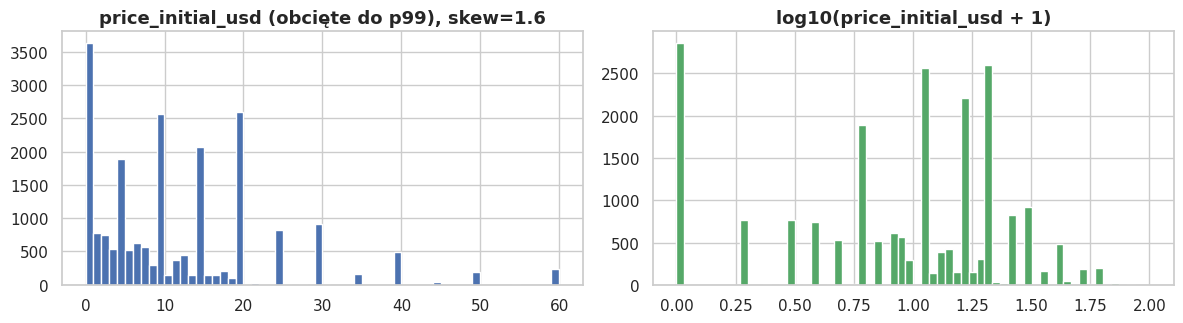

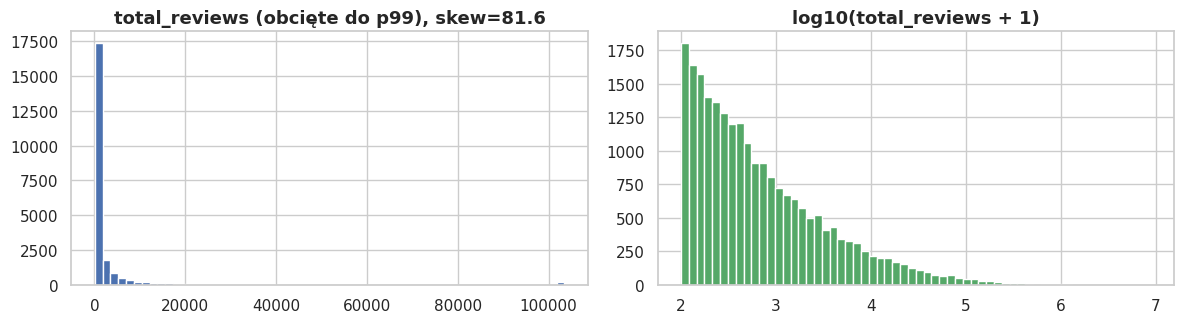

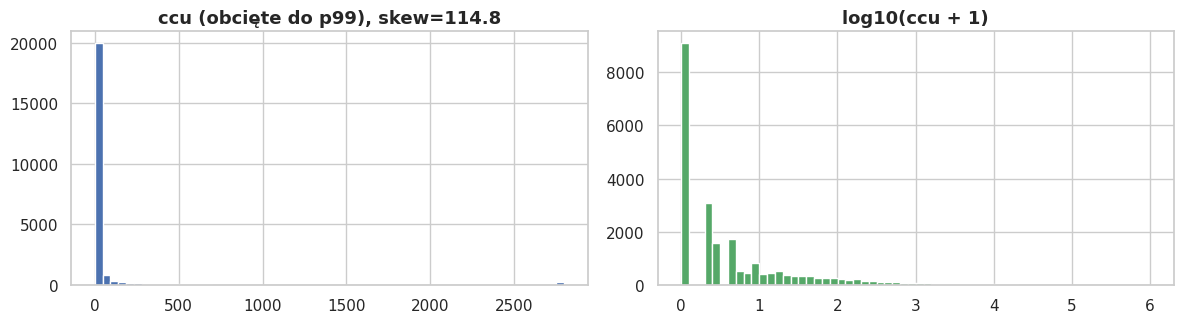

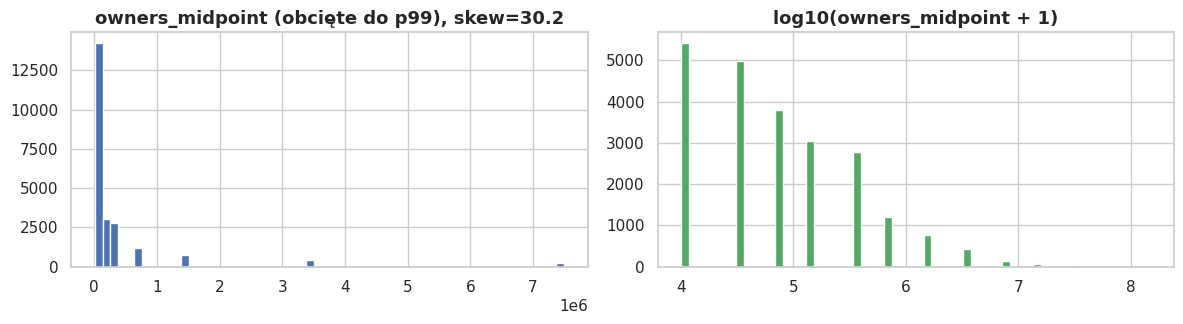

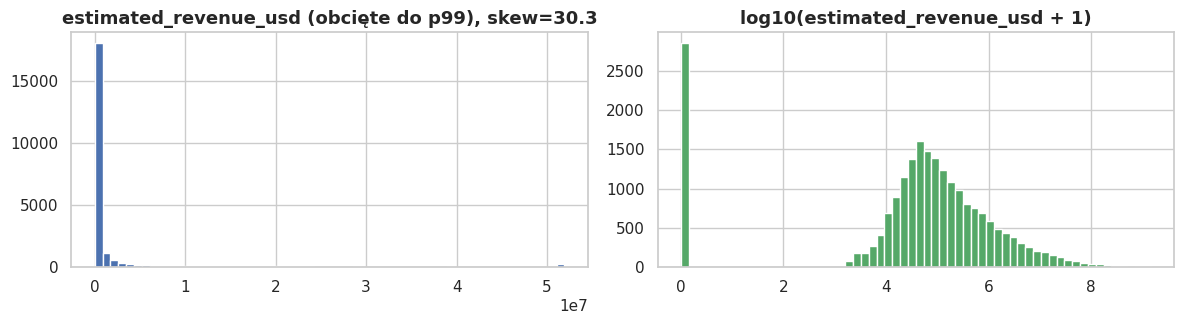

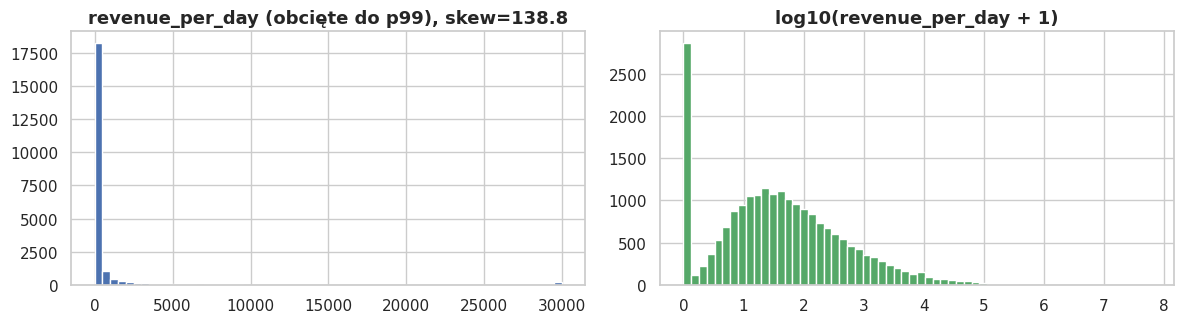

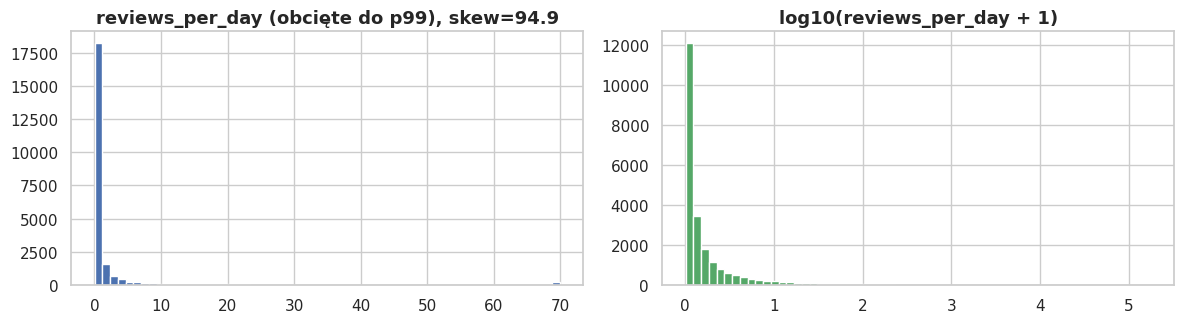

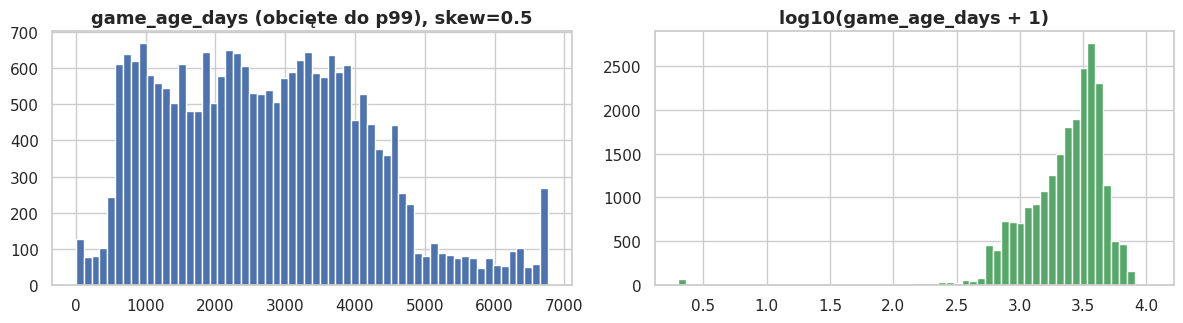

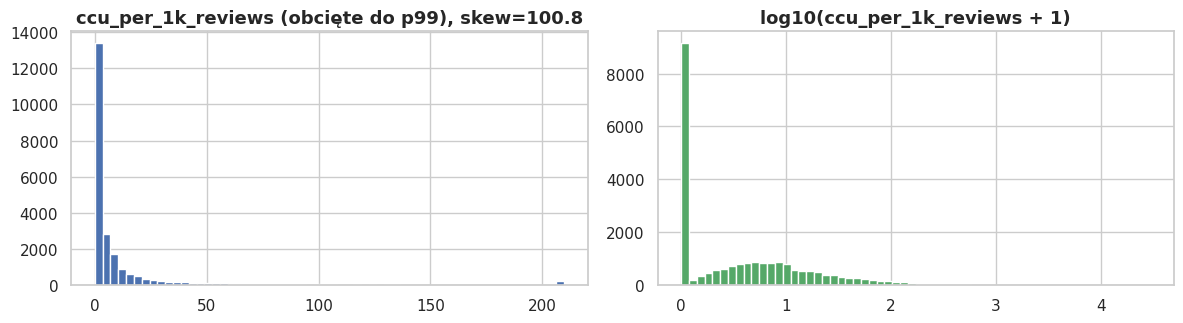

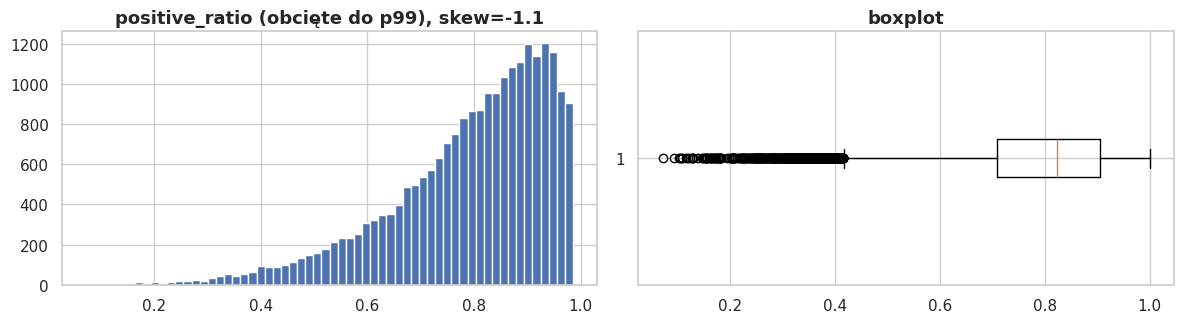

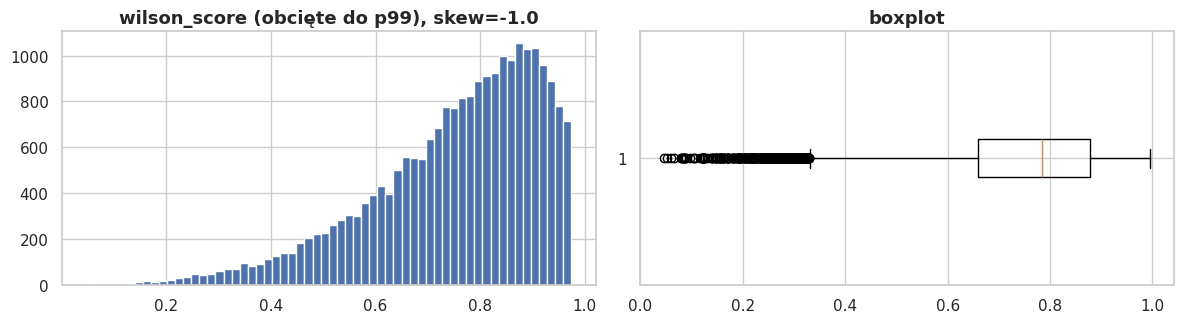

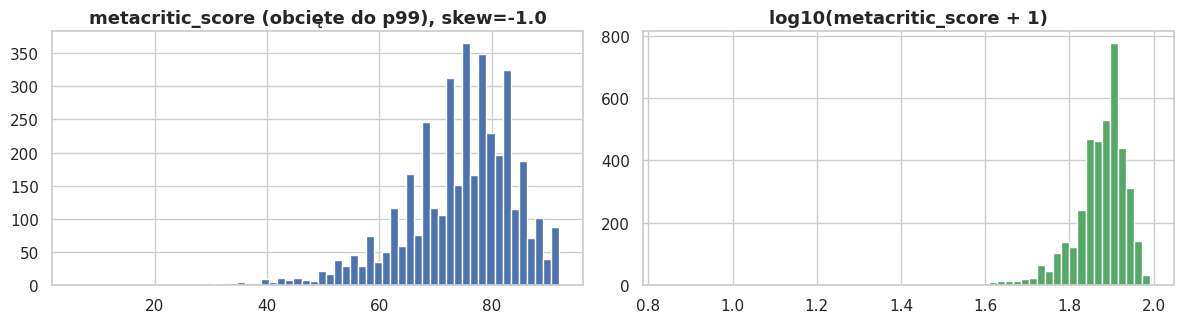

In [12]:
def dist_pair(col, bins=60):
    s = df[col].dropna()
    s = s[np.isfinite(s)]
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
    ax[0].hist(s.clip(upper=s.quantile(0.99)), bins=bins, color="#4C72B0")
    ax[0].set_title(f"{col} (obcięte do p99), skew={s.skew():.1f}")
    if (s >= 0).all() and s.max() > 50:
        ax[1].hist(np.log10(s + 1), bins=bins, color="#55A868")
        ax[1].set_title(f"log10({col} + 1)")
    else:
        ax[1].boxplot(s, vert=False); ax[1].set_title("boxplot")
    plt.tight_layout(); plt.show()

for c in ["price_initial_usd", "total_reviews", "ccu", "owners_midpoint", "estimated_revenue_usd",
          "revenue_per_day", "reviews_per_day", "game_age_days", "ccu_per_1k_reviews",
          "positive_ratio", "wilson_score", "metacritic_score"]:
    dist_pair(c)

## 5. Zmienne kategoryczne i binarne

### 5.1 Udział flag binarnych

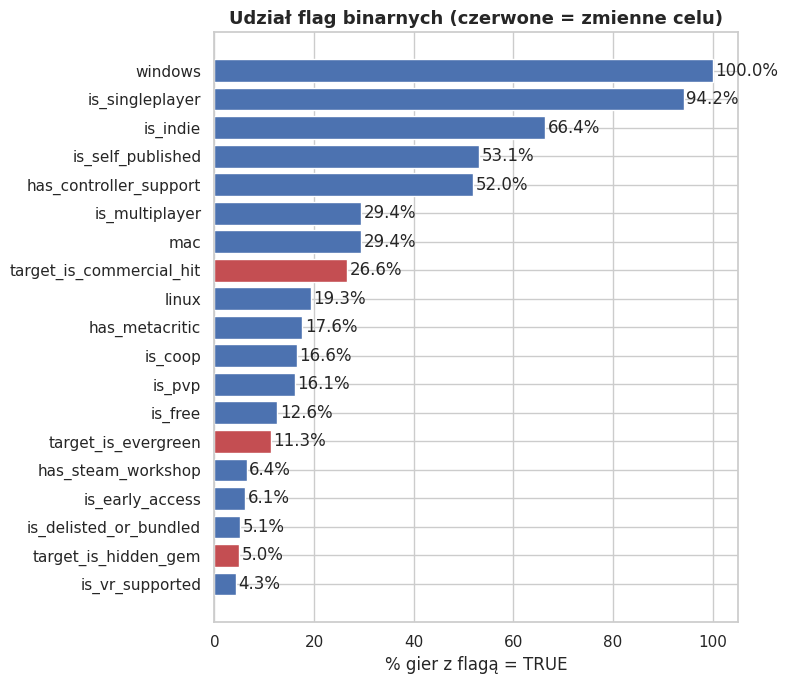

In [13]:
share = pd.Series({c: df[c].astype(float).mean() for c in BOOL_COLS}).sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
colors = ["#C44E52" if c in TARGET_BOOL else "#4C72B0" for c in share.index]
ax.barh(share.index, share.values * 100, color=colors)
for i, v in enumerate(share.values):
    ax.text(v * 100 + 0.5, i, f"{v*100:.1f}%", va="center")
ax.set_xlabel("% gier z flagą = TRUE"); ax.set_title("Udział flag binarnych (czerwone = zmienne celu)")
plt.tight_layout(); plt.show()

### 5.2 Platformy, wiek, liczba gatunków

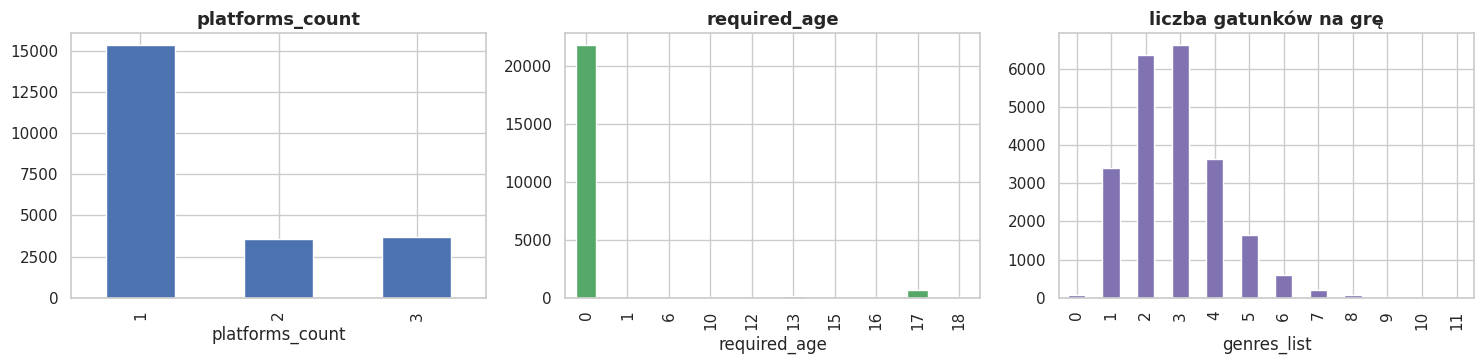

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
df.platforms_count.value_counts().sort_index().plot.bar(ax=ax[0], color="#4C72B0"); ax[0].set_title("platforms_count")
df.required_age.value_counts().sort_index().plot.bar(ax=ax[1], color="#55A868"); ax[1].set_title("required_age")
df.genres_list.str.len().value_counts().sort_index().plot.bar(ax=ax[2], color="#8172B2"); ax[2].set_title("liczba gatunków na grę")
plt.tight_layout(); plt.show()

### 5.3 Gatunki, kategorie, twórcy

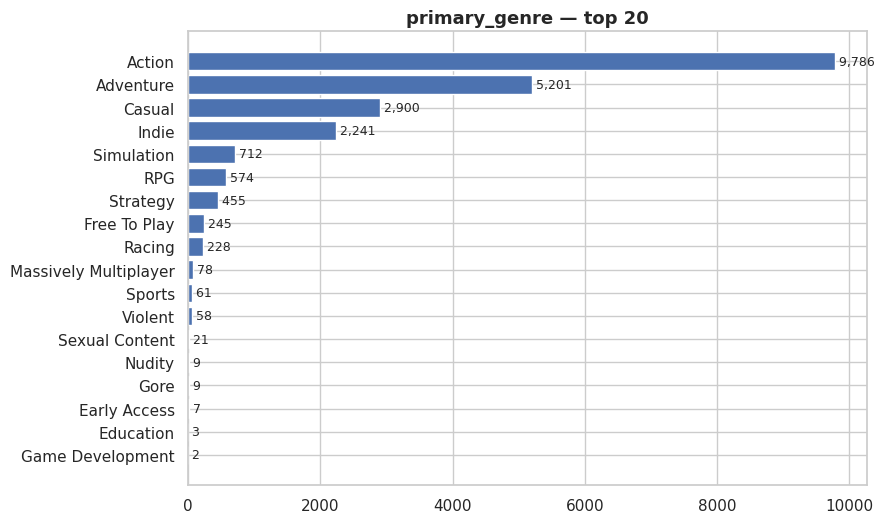

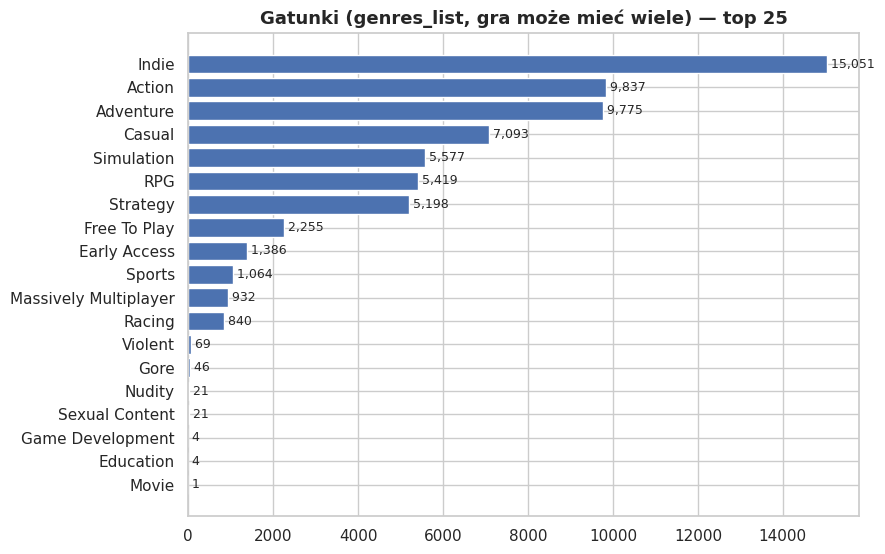

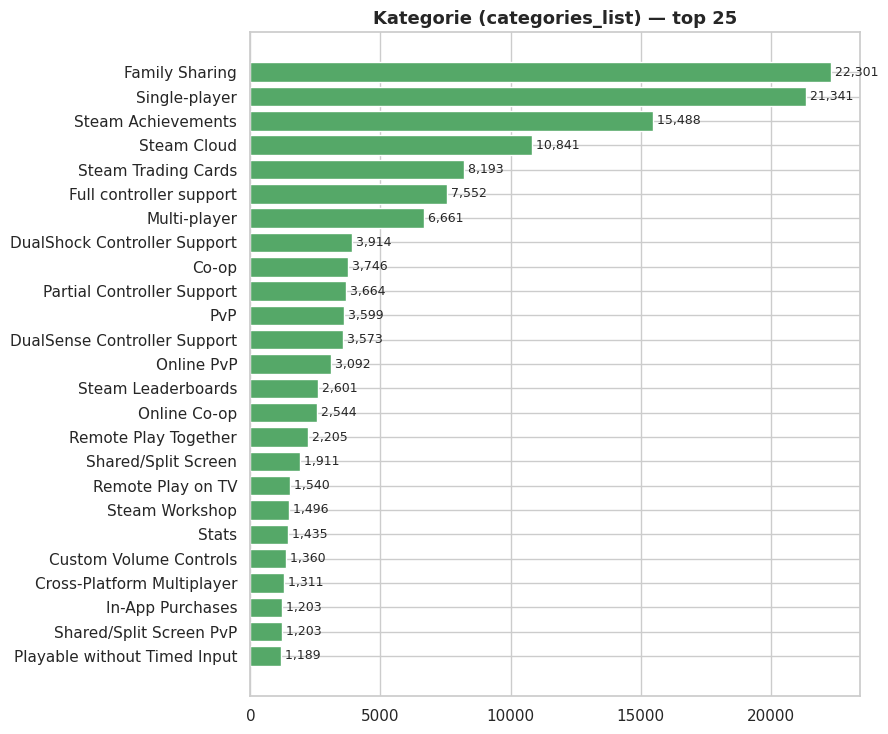

In [15]:
def barh_counts(series, title, n=25, color="#4C72B0"):
    s = series.head(n)[::-1]
    fig, ax = plt.subplots(figsize=(9, max(3, 0.3 * len(s))))
    ax.barh(s.index.astype(str), s.values, color=color)
    for i, v in enumerate(s.values):
        ax.text(v, i, f" {v:,}", va="center", fontsize=9)
    ax.set_title(title); plt.tight_layout(); plt.show()

barh_counts(df.primary_genre.value_counts(), "primary_genre — top 20", n=20)
barh_counts(df.genres_list.explode().value_counts(), "Gatunki (genres_list, gra może mieć wiele) — top 25")
barh_counts(df.categories_list.explode().value_counts(), "Kategorie (categories_list) — top 25", color="#55A868")

In [16]:
top_dev = df.developers.value_counts().head(15)
top_pub = df.publishers.value_counts().head(15)
display(pd.concat([top_dev.rename_axis("developer").reset_index(name="gier (developers)"),
                   top_pub.rename_axis("publisher").reset_index(name="gier (publishers)")], axis=1))
print(f"Unikalnych deweloperów: {df.developers.nunique():,} | wydawców: {df.publishers.nunique():,}")
print(f"Deweloperzy z 1 grą: {(df.developers.value_counts() == 1).mean()*100:.1f}% wszystkich deweloperów")

,developer,gier (developers),publisher,gier (publishers)
0,"KOEI TECMO GAMES CO., LTD.",82,Ubisoft,140
1,Square Enix,52,THQ Nordic,136
2,"CAPCOM Co., Ltd.",42,Square Enix,134
3,Milestone S.r.l.,41,Electronic Arts,124
4,Valve,32,Kagura Games,122
5,HeR Interactive,30,Devolver Digital,116
6,"Kairosoft Co.,Ltd",30,SEGA,116
7,Ripknot Systems,29,Fulqrum Publishing,95
8,Winged Cloud,29,Sekai Project,87
9,Telltale Games,28,Daedalic Entertainment,84


Unikalnych deweloperów: 14,149 | wydawców: 10,613
Deweloperzy z 1 grą: 75.8% wszystkich deweloperów


## 6. Analiza czasowa

Uwaga: `game_age_days` liczone jest względem daty uruchomienia pipeline'u — młode gry mają mniej czasu na zebranie recenzji, więc porównania „surowych” wolumenów między rocznikami są obciążone.

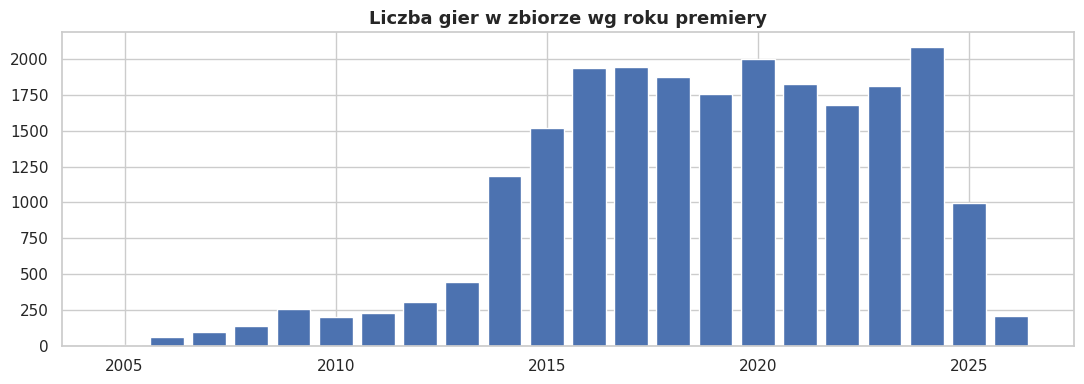

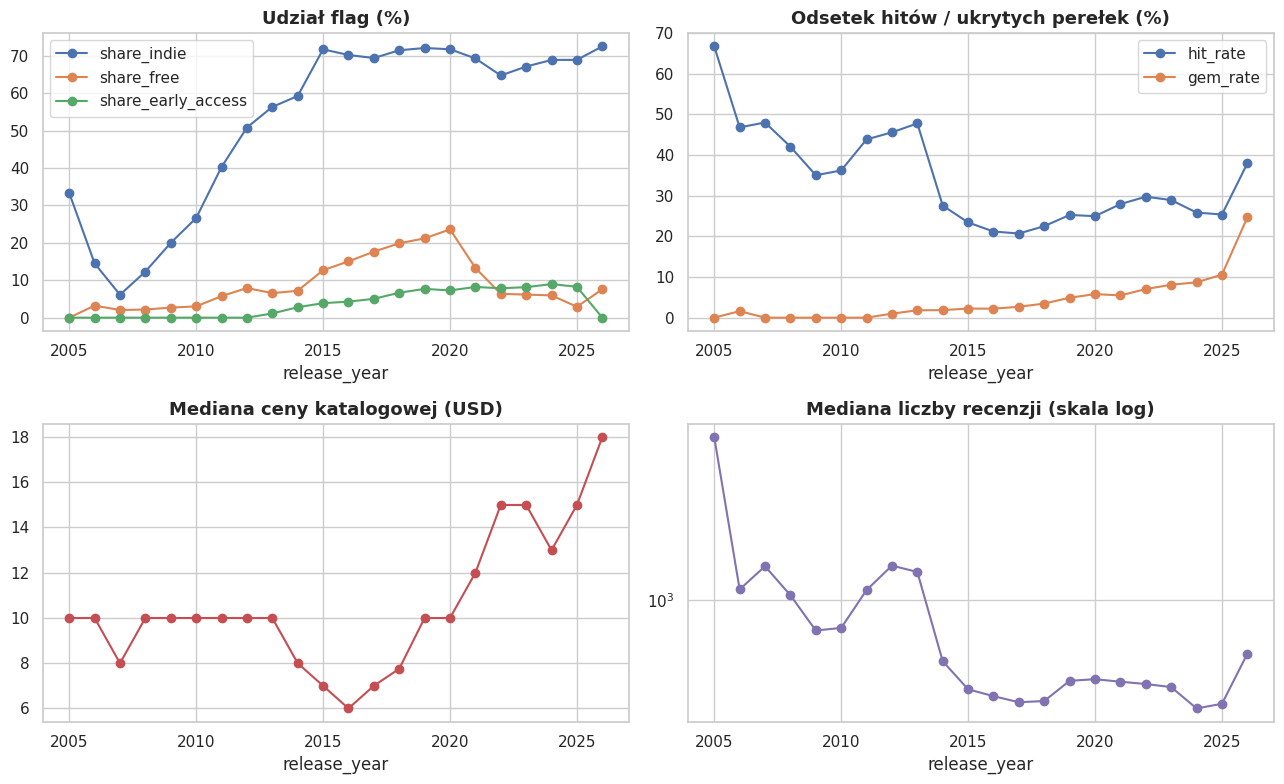

In [17]:
yr = (df.dropna(subset=["release_year"])
        .groupby("release_year")
        .agg(n_games=("app_id", "size"),
             median_price=("price_initial_usd", "median"),
             median_reviews=("total_reviews", "median"),
             median_pos_ratio=("positive_ratio", "median"),
             share_indie=("is_indie", "mean"),
             share_free=("is_free", "mean"),
             share_early_access=("is_early_access", "mean"),
             hit_rate=("target_is_commercial_hit", "mean"),
             gem_rate=("target_is_hidden_gem", "mean"))
        .astype(float))
yr = yr[yr.index >= 2005]

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(yr.index, yr.n_games, color="#4C72B0"); ax.set_title("Liczba gier w zbiorze wg roku premiery")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
yr[["share_indie", "share_free", "share_early_access"]].mul(100).plot(ax=ax[0, 0], marker="o"); ax[0, 0].set_title("Udział flag (%)")
yr[["hit_rate", "gem_rate"]].mul(100).plot(ax=ax[0, 1], marker="o"); ax[0, 1].set_title("Odsetek hitów / ukrytych perełek (%)")
yr["median_price"].plot(ax=ax[1, 0], marker="o", color="#C44E52"); ax[1, 0].set_title("Mediana ceny katalogowej (USD)")
yr["median_reviews"].plot(ax=ax[1, 1], marker="o", color="#8172B2", logy=True); ax[1, 1].set_title("Mediana liczby recenzji (skala log)")
plt.tight_layout(); plt.show()

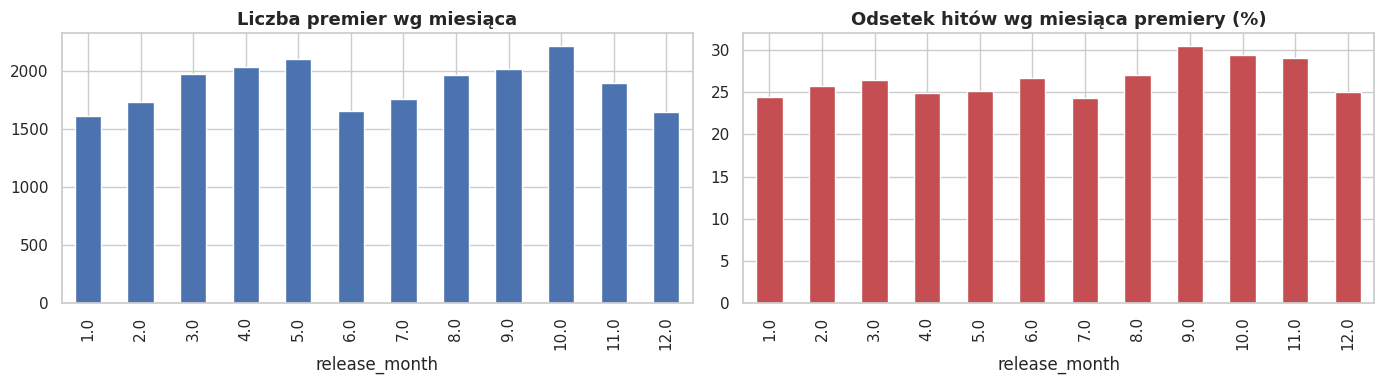

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df.release_month.value_counts().sort_index().plot.bar(ax=ax[0], color="#4C72B0"); ax[0].set_title("Liczba premier wg miesiąca")
mm = df.groupby("release_month")["target_is_commercial_hit"].mean().astype(float) * 100
mm.plot.bar(ax=ax[1], color="#C44E52"); ax[1].set_title("Odsetek hitów wg miesiąca premiery (%)")
plt.tight_layout(); plt.show()

## 7. Cena i ekonomia

In [19]:
grp = df.groupby(df["is_free"].map({True: "darmowe", False: "płatne"}))
display(grp.agg(n=("app_id", "size"), median_reviews=("total_reviews", "median"),
                median_pos_ratio=("positive_ratio", "median"), median_ccu=("ccu", "median"),
                median_owners_mid=("owners_midpoint", "median"),
                hit_rate=("target_is_commercial_hit", "mean"),
                evergreen_rate=("target_is_evergreen", "mean")))
print(f"Gry wycofane / pakietowe (bez ceny): {df.is_delisted_or_bundled.astype(float).sum():,.0f} "
      f"({df.is_delisted_or_bundled.astype(float).mean()*100:.1f}%)")

,n,median_reviews,median_pos_ratio,median_ccu,median_owners_mid,hit_rate,evergreen_rate
is_free,,,,,,,
darmowe,2856,443.000,0.792,1.000,"75,000.000",0.000,0.122
płatne,19799,450.000,0.828,1.000,"75,000.000",0.305,0.111


Gry wycofane / pakietowe (bez ceny): 1,156 (5.1%)


,n,median_reviews,median_pos_ratio,median_rev_per_day,hit_rate,gem_rate
price_band,,,,,,
<1,768,235.000,0.794,1.952,0.121,0.036
1-5,3956,281.000,0.816,8.670,0.168,0.041
5-10,4587,355.000,0.835,28.113,0.246,0.047
10-15,3182,412.000,0.847,67.348,0.299,0.060
15-20,3190,753.000,0.842,183.907,0.442,0.065
20-30,1814,"1,392.500",0.830,488.544,0.568,0.072
30-60,1102,"2,922.500",0.829,"1,651.026",0.656,0.020
60+,44,"4,390.500",0.748,"6,297.408",0.750,0.000


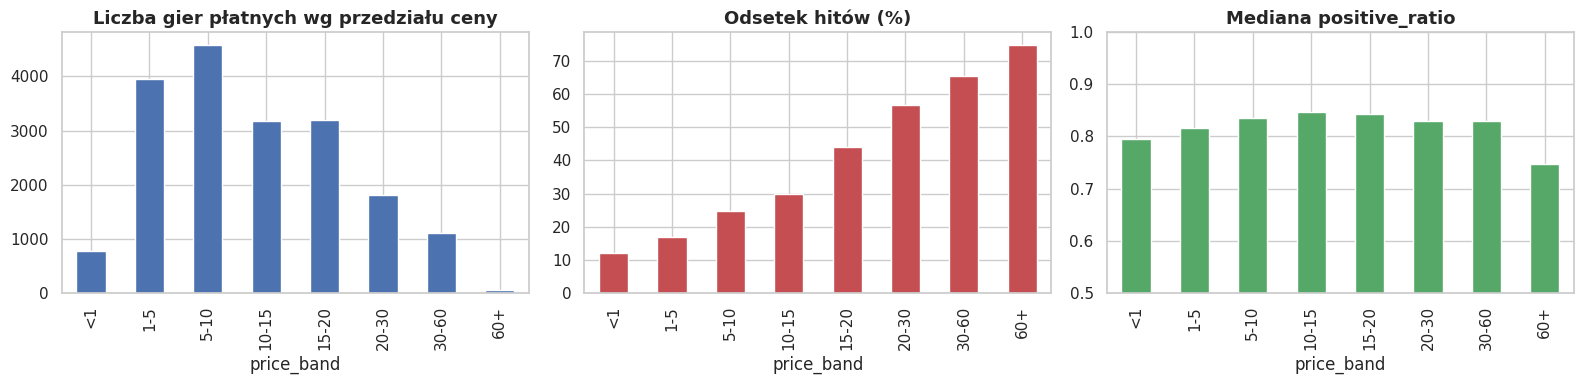

In [20]:
pb = (df.groupby("price_band", observed=True)
        .agg(n=("app_id", "size"), median_reviews=("total_reviews", "median"),
             median_pos_ratio=("positive_ratio", "median"), median_rev_per_day=("revenue_per_day", "median"),
             hit_rate=("target_is_commercial_hit", "mean"), gem_rate=("target_is_hidden_gem", "mean"))
        .astype({"hit_rate": float, "gem_rate": float}))
display(pb)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
pb["n"].plot.bar(ax=ax[0], color="#4C72B0"); ax[0].set_title("Liczba gier płatnych wg przedziału ceny")
(pb["hit_rate"] * 100).plot.bar(ax=ax[1], color="#C44E52"); ax[1].set_title("Odsetek hitów (%)")
pb["median_pos_ratio"].plot.bar(ax=ax[2], color="#55A868"); ax[2].set_title("Mediana positive_ratio"); ax[2].set_ylim(0.5, 1)
plt.tight_layout(); plt.show()

### 7.1 Koncentracja przychodów (efekt „winner takes all”)

Gier z przychodem > 0: 18,643 | łączny szac. przychód: 59.4 mld USD | Gini = 0.937
  top   0.1% gier (    18) ->  21.2% przychodu
  top   1.0% gier (   186) ->  58.2% przychodu
  top   5.0% gier (   932) ->  84.9% przychodu
  top  10.0% gier ( 1,864) ->  92.2% przychodu
  top  20.0% gier ( 3,728) ->  96.7% przychodu


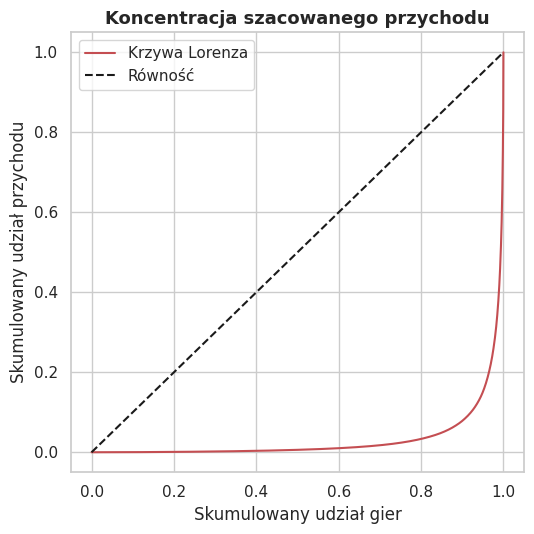

In [21]:
def gini(x):
    x = np.sort(np.asarray(x, dtype=float)); n = len(x); cum = np.cumsum(x)
    return (n + 1 - 2 * cum.sum() / cum[-1]) / n

rev = df["estimated_revenue_usd"].dropna()
rev = rev[rev > 0].sort_values(ascending=False)
tot = rev.sum()
print(f"Gier z przychodem > 0: {len(rev):,} | łączny szac. przychód: {tot/1e9:,.1f} mld USD | Gini = {gini(rev):.3f}")
for q in [0.001, 0.01, 0.05, 0.10, 0.20]:
    k = max(1, int(len(rev) * q))
    print(f"  top {q*100:>5.1f}% gier ({k:>6,}) -> {rev.iloc[:k].sum()/tot*100:5.1f}% przychodu")

asc = np.sort(rev.values)
lorenz = np.insert(np.cumsum(asc) / asc.sum(), 0, 0)
x = np.linspace(0, 1, len(lorenz))
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot(x, lorenz, color="#C44E52", label="Krzywa Lorenza"); ax.plot([0, 1], [0, 1], "k--", label="Równość")
ax.set_xlabel("Skumulowany udział gier"); ax.set_ylabel("Skumulowany udział przychodu"); ax.legend()
ax.set_title("Koncentracja szacowanego przychodu"); plt.tight_layout(); plt.show()

## 8. Jakość (oceny) a liczba recenzji

,n,mean_pos_ratio,median_pos_ratio,median_wilson,unmet
volume_band,,,,,
100-499,11942,0.766,0.798,0.738,1.247
500-999,3301,0.790,0.821,0.791,1.373
1k-10k,5673,0.820,0.853,0.838,1.406
10k+,1739,0.855,0.892,0.887,1.490


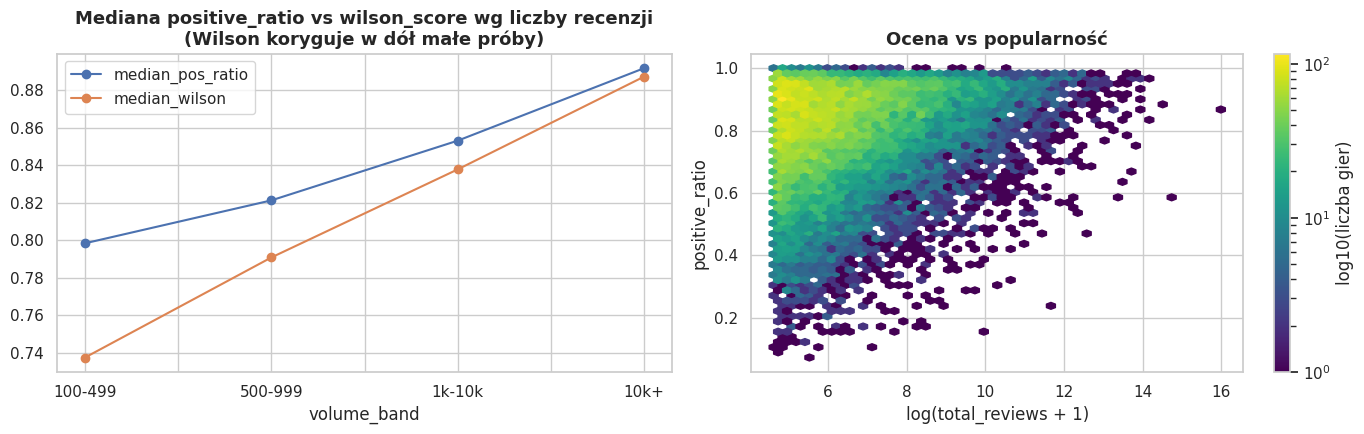

In [22]:
vb = (df.groupby("volume_band", observed=True)
        .agg(n=("app_id", "size"), mean_pos_ratio=("positive_ratio", "mean"),
             median_pos_ratio=("positive_ratio", "median"), median_wilson=("wilson_score", "median"),
             unmet=("target_unmet_demand_score", "mean")))
display(vb)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
vb[["median_pos_ratio", "median_wilson"]].plot(ax=ax[0], marker="o")
ax[0].set_title("Mediana positive_ratio vs wilson_score wg liczby recenzji\n(Wilson koryguje w dół małe próby)")
hb = ax[1].hexbin(df.log_total_reviews, df.positive_ratio, gridsize=50, cmap="viridis", mincnt=1, bins="log")
ax[1].set_xlabel("log(total_reviews + 1)"); ax[1].set_ylabel("positive_ratio"); ax[1].set_title("Ocena vs popularność")
plt.colorbar(hb, ax=ax[1], label="log10(liczba gier)")
plt.tight_layout(); plt.show()

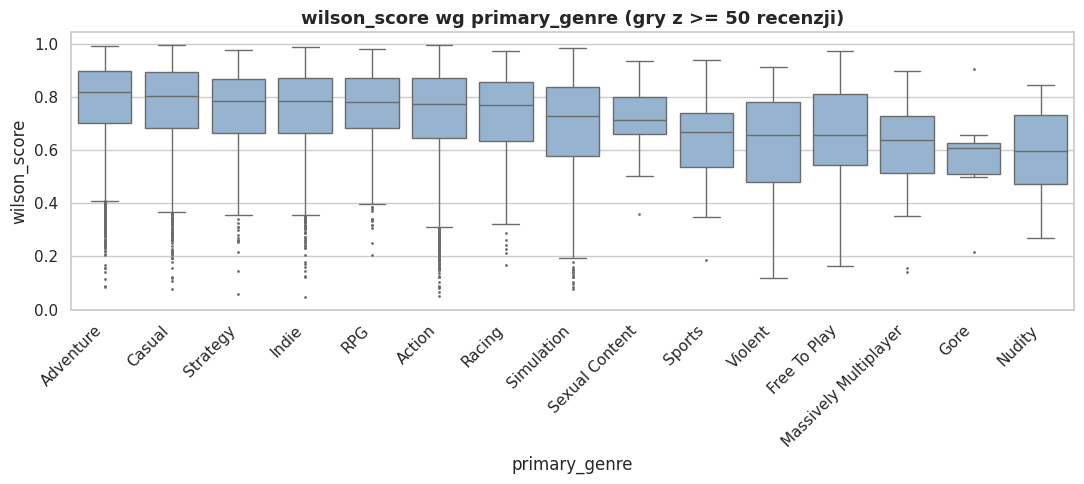

In [23]:
top_g = df.primary_genre.value_counts().head(15).index
sub = df[df.primary_genre.isin(top_g) & (df.total_reviews >= 50)]
order = sub.groupby("primary_genre")["wilson_score"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=sub, x="primary_genre", y="wilson_score", order=order, color="#8CB4D9", fliersize=1, ax=ax)
ax.set_title("wilson_score wg primary_genre (gry z >= 50 recenzji)"); plt.xticks(rotation=45, ha="right")
plt.tight_layout(); plt.show()

## 9. Posiadacze vs recenzje (weryfikacja mnożnika Boxleitera)

Metoda Boxleitera zakłada ~30 sprzedanych kopii na 1 recenzję. Dane `owners_*` (SteamSpy) pozwalają to sprawdzić empirycznie. Uwaga: SteamSpy podaje szerokie, dyskretne przedziały, więc `owners_midpoint` jest bardzo zgrubny.

Unikalnych wartości owners_midpoint: 13
Implikowany mnożnik owners/recenzje: mediana = 95.2, p25 = 57.1, p75 = 202.6


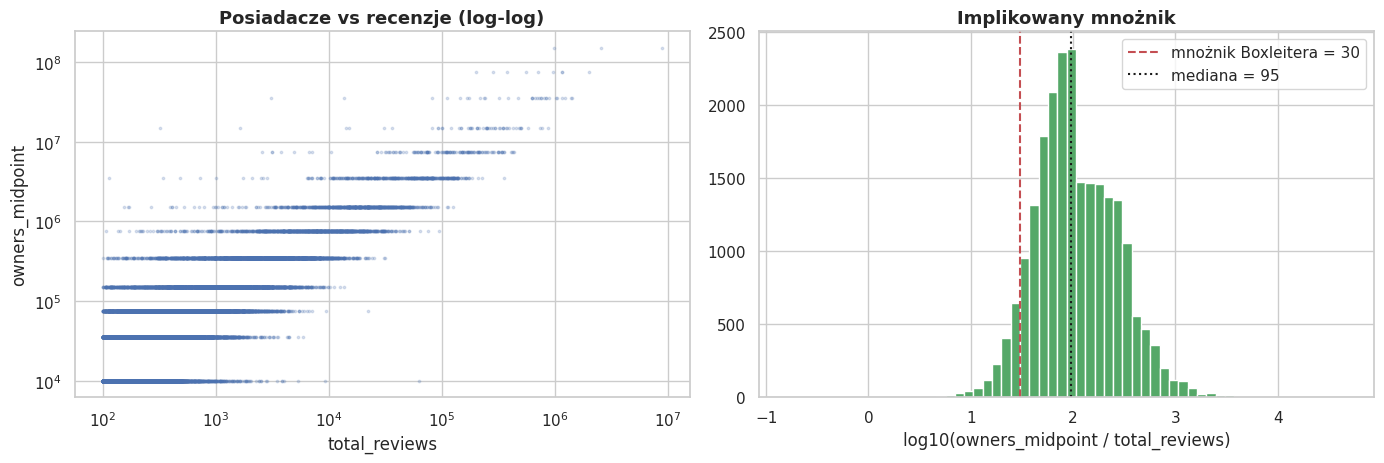

In [24]:
m = (df.owners_midpoint / df.total_reviews).replace([np.inf, -np.inf], np.nan)
m = m[m > 0].dropna()
print(f"Unikalnych wartości owners_midpoint: {df.owners_midpoint.nunique()}")
print(f"Implikowany mnożnik owners/recenzje: mediana = {m.median():.1f}, p25 = {m.quantile(.25):.1f}, p75 = {m.quantile(.75):.1f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
smp = df[(df.owners_midpoint > 0)].sample(min(30000, len(df)), random_state=RANDOM_STATE)
ax[0].scatter(smp.total_reviews, smp.owners_midpoint, s=3, alpha=0.2, color="#4C72B0")
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("total_reviews"); ax[0].set_ylabel("owners_midpoint"); ax[0].set_title("Posiadacze vs recenzje (log-log)")
ax[1].hist(np.log10(m), bins=60, color="#55A868")
ax[1].axvline(np.log10(30), color="#C44E52", ls="--", label="mnożnik Boxleitera = 30")
ax[1].axvline(np.log10(m.median()), color="k", ls=":", label=f"mediana = {m.median():.0f}")
ax[1].set_xlabel("log10(owners_midpoint / total_reviews)"); ax[1].legend(); ax[1].set_title("Implikowany mnożnik")
plt.tight_layout(); plt.show()

In [25]:
# Czy mnożnik zależy od ceny / popularności? (jeśli tak, stała 30 w estimated_revenue_usd jest uproszczeniem)
tmp = df.assign(mult=df.owners_midpoint / df.total_reviews)
display(tmp.groupby("volume_band", observed=True)["mult"].median().rename("mediana mnożnika wg liczby recenzji").to_frame())
display(tmp.groupby("price_band", observed=True)["mult"].median().rename("mediana mnożnika wg ceny").to_frame())

,mediana mnożnika wg liczby recenzji
volume_band,
100-499,107.692
500-999,108.225
1k-10k,86.978
10k+,54.761


,mediana mnożnika wg ceny
price_band,
<1,127.489
1-5,118.317
5-10,104.822
10-15,87.032
15-20,76.923
20-30,65.858
30-60,54.056
60+,36.905


## 10. Zmienne celu (targety)

### 10.1 Rozkłady i balans klas

,n_TRUE,% TRUE
target_is_commercial_hit,"6,032.000",26.625
target_is_hidden_gem,"1,136.000",5.014
target_is_evergreen,"2,551.000",11.260


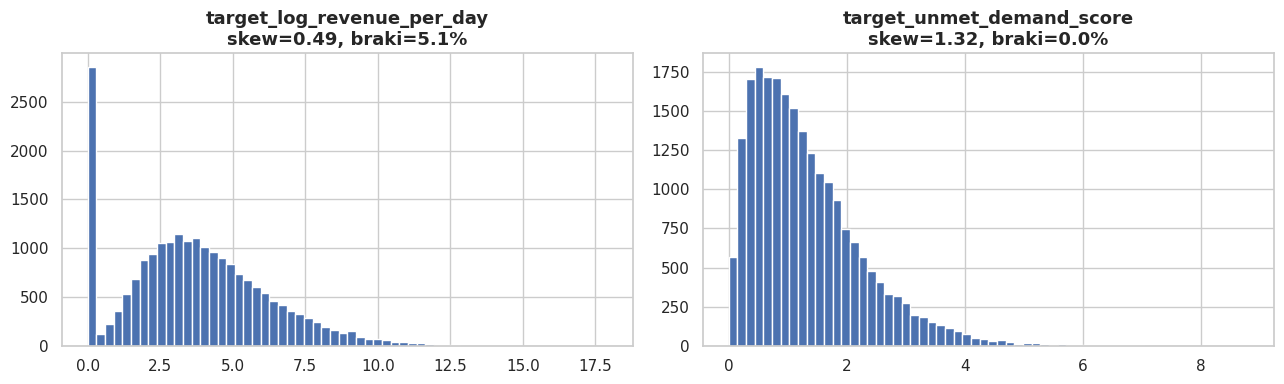

In [26]:
bal = pd.DataFrame({t: {"n_TRUE": int(df[t].astype(float).sum()), "% TRUE": df[t].astype(float).mean() * 100}
                    for t in TARGET_BOOL}).T
display(bal)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, t in zip(ax, TARGET_NUM):
    a.hist(df[t].dropna(), bins=60, color="#4C72B0"); a.set_title(f"{t}\nskew={df[t].skew():.2f}, braki={df[t].isna().mean()*100:.1f}%")
plt.tight_layout(); plt.show()

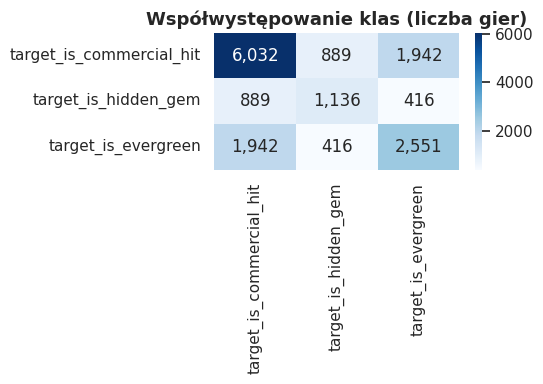

In [27]:
# Współwystępowanie klas pozytywnych
co = pd.DataFrame({a: {b: (df[a].fillna(False).astype(bool) & df[b].fillna(False).astype(bool)).sum() for b in TARGET_BOOL}
                   for a in TARGET_BOOL})
plt.figure(figsize=(5.5, 4)); sns.heatmap(co, annot=True, fmt=",d", cmap="Blues"); plt.title("Współwystępowanie klas (liczba gier)")
plt.tight_layout(); plt.show()

### 10.2 Targety wg gatunku, roku i cech

,n,hit_rate,gem_rate,evergreen_rate,mean_unmet,mean_log_rev_day
primary_genre,,,,,,
Action,9786,0.306,0.049,0.125,1.451,3.944
Adventure,5201,0.242,0.057,0.066,1.082,3.577
Casual,2900,0.178,0.067,0.087,1.120,2.828
Indie,2241,0.243,0.070,0.091,1.259,3.830
Simulation,712,0.309,0.000,0.242,1.794,4.694
RPG,574,0.392,0.000,0.232,1.385,4.883
Strategy,455,0.338,0.000,0.248,1.430,4.221
Free To Play,245,0.000,0.020,0.037,1.763,0.000
Racing,228,0.351,0.000,0.193,1.622,4.711


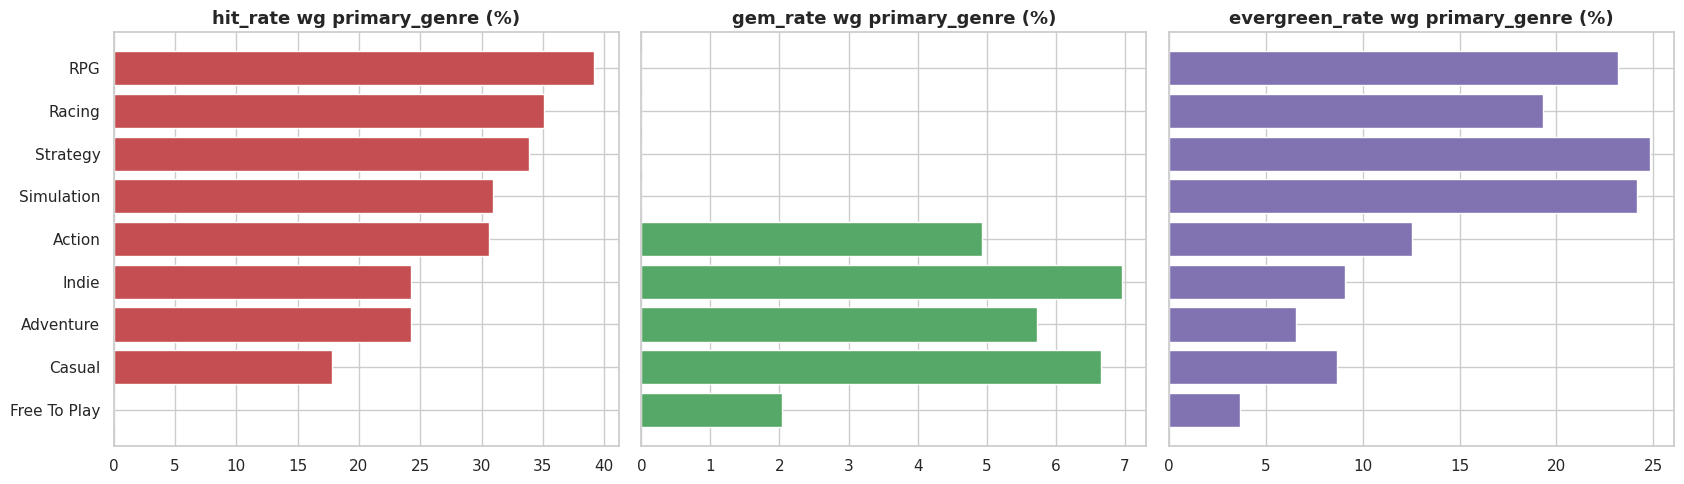

In [28]:
def rate_table(by, n_min=50, top=None):
    t = (df.groupby(by, observed=True)
           .agg(n=("app_id", "size"),
                hit_rate=("target_is_commercial_hit", "mean"),
                gem_rate=("target_is_hidden_gem", "mean"),
                evergreen_rate=("target_is_evergreen", "mean"),
                mean_unmet=("target_unmet_demand_score", "mean"),
                mean_log_rev_day=("target_log_revenue_per_day", "mean")))
    t = t[t.n >= n_min]
    for c in ["hit_rate", "gem_rate", "evergreen_rate"]:
        t[c] = t[c].astype(float)
    return t

pg = rate_table("primary_genre", n_min=100).sort_values("n", ascending=False).head(20)
display(pg)
fig, ax = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
for a, c, col in zip(ax, ["hit_rate", "gem_rate", "evergreen_rate"], ["#C44E52", "#55A868", "#8172B2"]):
    s = pg[c].sort_values() * 100
    a.barh(s.index, s.values, color=col); a.set_title(f"{c} wg primary_genre (%)")
plt.tight_layout(); plt.show()

In [29]:
# Wpływ flag binarnych na prawdopodobieństwo targetów (lift = P(target | flaga=TRUE) / P(target | flaga=FALSE))
flags = [c for c in BOOL_FLAGS if c not in ("is_free", "is_delisted_or_bundled", "has_metacritic")]
rows = []
for f in flags:
    fb = df[f].fillna(False).astype(bool)
    r = {"flag": f, "% TRUE": fb.mean() * 100}
    for t in TARGET_BOOL:
        y = df[t].astype(float)
        p1, p0 = y[fb].mean(), y[~fb].mean()
        r[t.replace("target_is_", "") + " | TRUE (%)"] = p1 * 100
        r[t.replace("target_is_", "") + " | FALSE (%)"] = p0 * 100
        r[t.replace("target_is_", "") + " lift"] = p1 / p0 if p0 > 0 else np.nan
    rows.append(r)
lift = pd.DataFrame(rows).set_index("flag")
display(lift.style.background_gradient(subset=[c for c in lift.columns if c.endswith("lift")], cmap="RdYlGn", vmin=0, vmax=3))

,% TRUE,commercial_hit | TRUE (%),commercial_hit | FALSE (%),commercial_hit lift,hidden_gem | TRUE (%),hidden_gem | FALSE (%),hidden_gem lift,evergreen | TRUE (%),evergreen | FALSE (%),evergreen lift
flag,,,,,,,,,,
windows,99.986758,26.628995,0.000000,nan,5.015010,0.000000,nan,11.261699,0.000000,nan
mac,29.375414,29.737040,25.331250,1.173927,6.806912,4.268750,1.594591,11.600301,11.118750,1.043310
linux,19.293754,29.627088,25.907898,1.143554,5.902539,4.802013,1.229180,10.889957,11.348720,0.959576
is_indie,66.435665,23.420371,32.969490,0.710365,7.547671,0.000000,nan,7.155671,19.384534,0.369143
is_early_access,6.117855,19.769120,27.072265,0.730235,5.916306,4.955569,1.193870,12.265512,11.194697,1.095654
is_singleplayer,94.199956,27.327679,15.220700,1.795429,5.102854,3.576865,1.426628,10.800806,18.721461,0.576921
is_multiplayer,29.401898,32.427563,24.209078,1.339479,4.698994,5.145680,0.913192,20.027023,7.609103,2.631982
is_coop,16.561465,37.793177,24.408824,1.548341,6.316631,4.755859,1.328179,23.507463,8.829286,2.662442
is_pvp,16.102406,29.523026,26.069343,1.132481,4.687500,5.077077,0.923267,20.422149,9.501763,2.149301


## 11. Korelacje i ryzyko wycieku danych

### 11.1 Korelacje Spearmana między zmiennymi numerycznymi

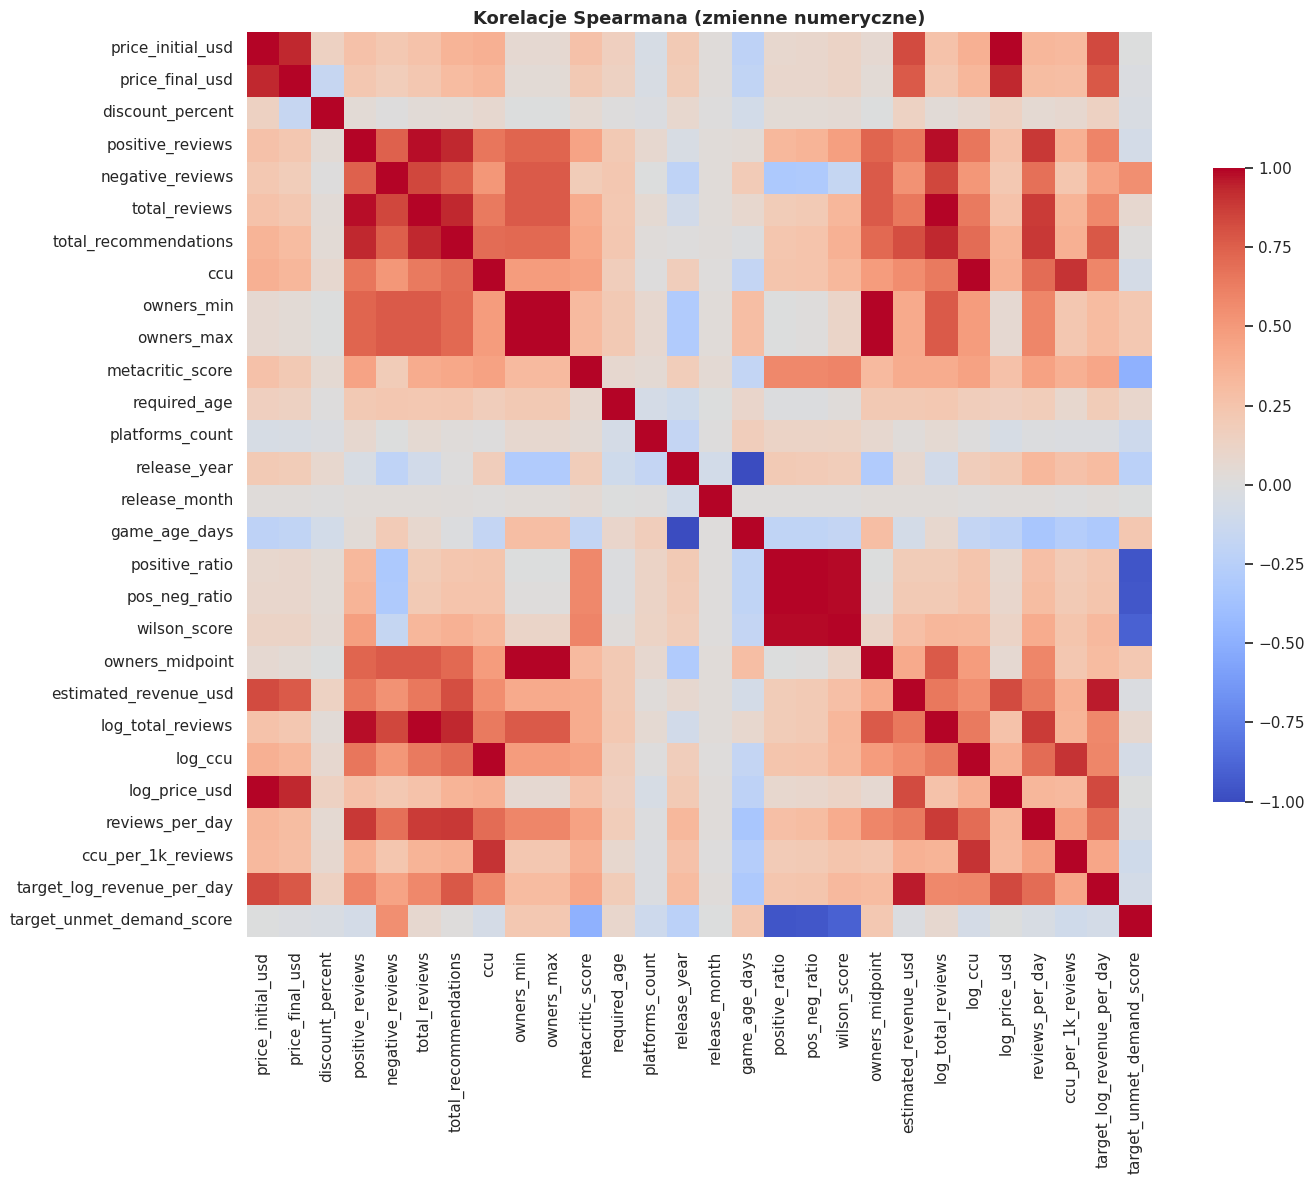

Pary silnie skorelowane (|rho| >= 0.9) — kandydaci do usunięcia przy modelowaniu liniowym:


,zmienna_1,zmienna_2,rho
0,price_initial_usd,log_price_usd,1.000
1,owners_max,owners_midpoint,1.000
2,ccu,log_ccu,1.000
3,owners_min,owners_max,1.000
4,owners_min,owners_midpoint,1.000
5,total_reviews,log_total_reviews,1.000
6,positive_ratio,pos_neg_ratio,1.000
7,release_year,game_age_days,-0.997
8,pos_neg_ratio,wilson_score,0.990
9,positive_ratio,wilson_score,0.987


In [30]:
corr_cols = [c for c in NUM_COLS if df[c].nunique() > 1]
sp = df[corr_cols].corr(method="spearman")
plt.figure(figsize=(15, 12))
sns.heatmap(sp, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, cbar_kws={"shrink": .7},
            xticklabels=True, yticklabels=True)
plt.title("Korelacje Spearmana (zmienne numeryczne)"); plt.tight_layout(); plt.show()

pairs = sp.where(np.triu(np.ones(sp.shape, dtype=bool), k=1)).stack().rename("rho").reset_index()
pairs.columns = ["zmienna_1", "zmienna_2", "rho"]
print("Pary silnie skorelowane (|rho| >= 0.9) — kandydaci do usunięcia przy modelowaniu liniowym:")
display(pairs[pairs.rho.abs() >= 0.9].sort_values("rho", key=abs, ascending=False).reset_index(drop=True))

### 11.2 Zależność cech od targetów + oznaczenie zmiennych „przeciekających”

Targety są **funkcjami innych kolumn** (definicje w słowniku). Cechy, z których target jest bezpośrednio policzony,
dadzą sztucznie wysoką korelację i zawyżą jakość modelu — należy je wyłączyć z zestawu cech dla danego targetu.

Korelacje bez zmiennych przeciekających (puste = cecha jest wejściem definicji targetu):


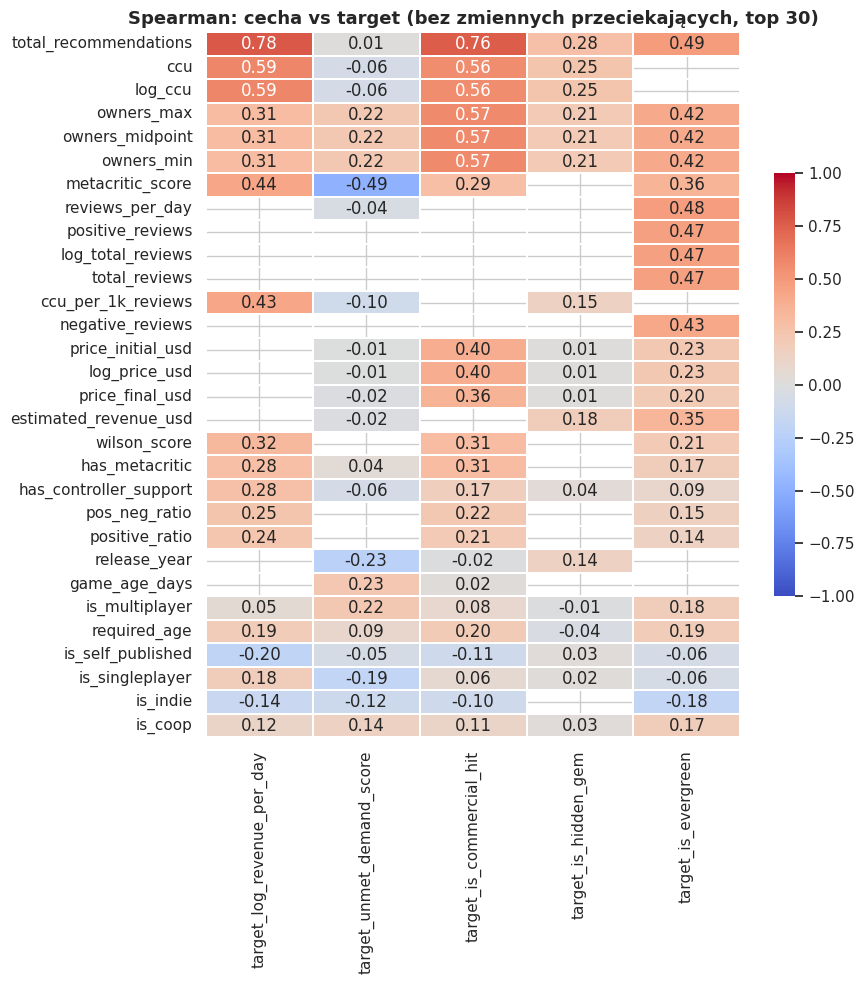

In [31]:
LEAK = {
    "target_log_revenue_per_day": {"estimated_revenue_usd", "revenue_per_day", "total_reviews", "log_total_reviews",
                                   "positive_reviews", "negative_reviews", "price_initial_usd", "price_final_usd",
                                   "log_price_usd", "game_age_days", "reviews_per_day", "is_free", "is_delisted_or_bundled",
                                   "release_year", "release_month"},
    "target_unmet_demand_score": {"total_reviews", "log_total_reviews", "positive_reviews", "negative_reviews",
                                  "positive_ratio", "pos_neg_ratio", "wilson_score"},
    "target_is_commercial_hit": {"is_free", "is_delisted_or_bundled", "total_reviews", "log_total_reviews",
                                 "positive_reviews", "negative_reviews", "estimated_revenue_usd", "revenue_per_day",
                                 "reviews_per_day", "ccu_per_1k_reviews"},
    "target_is_hidden_gem": {"is_indie", "has_metacritic", "metacritic_score", "wilson_score", "positive_ratio",
                             "pos_neg_ratio", "reviews_per_day", "positive_reviews", "negative_reviews",
                             "total_reviews", "log_total_reviews", "game_age_days"},
    "target_is_evergreen": {"game_age_days", "release_year", "release_month", "ccu", "log_ccu", "ccu_per_1k_reviews"},
}
feat = pd.concat([df[NUM_FEATURES], df[[c for c in BOOL_FLAGS if c in df.columns]].astype(float)], axis=1)
feat = feat.loc[:, feat.nunique() > 1]
tg = pd.concat([df[TARGET_NUM], df[TARGET_BOOL].astype(float)], axis=1)
cor_all = pd.DataFrame({t: feat.corrwith(tg[t], method="spearman") for t in TARGETS})
cor_safe = cor_all.copy()
for t, leak in LEAK.items():
    cor_safe.loc[cor_safe.index.isin(leak), t] = np.nan

print("Korelacje bez zmiennych przeciekających (puste = cecha jest wejściem definicji targetu):")
order = cor_safe.abs().max(axis=1).sort_values(ascending=False).index[:30]
plt.figure(figsize=(9, 10))
sns.heatmap(cor_safe.loc[order], annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            cbar_kws={"shrink": .6}, linewidths=.3, linecolor="white")
plt.title("Spearman: cecha vs target (bez zmiennych przeciekających, top 30)")
plt.tight_layout(); plt.show()

In [32]:
# Dla porównania — jak bardzo „przeciekające” cechy zawyżają korelacje
leak_view = {t: cor_all.loc[sorted(set(cor_all.index) & LEAK[t]), t].sort_values(key=abs, ascending=False).head(5)
             for t in TARGETS}
for t, s in leak_view.items():
    print(f"\n{t} — najsilniejsze „przeciekające” cechy:")
    display(s.to_frame("rho"))


target_log_revenue_per_day — najsilniejsze „przeciekające” cechy:


,rho
estimated_revenue_usd,0.959
log_price_usd,0.831
price_initial_usd,0.831
price_final_usd,0.780
reviews_per_day,0.701



target_unmet_demand_score — najsilniejsze „przeciekające” cechy:


,rho
positive_ratio,-0.957
pos_neg_ratio,-0.952
wilson_score,-0.901
negative_reviews,0.553
total_reviews,0.075



target_is_commercial_hit — najsilniejsze „przeciekające” cechy:


,rho
estimated_revenue_usd,0.734
total_reviews,0.701
log_total_reviews,0.701
positive_reviews,0.701
reviews_per_day,0.659



target_is_hidden_gem — najsilniejsze „przeciekające” cechy:


,rho
reviews_per_day,0.306
wilson_score,0.292
positive_reviews,0.286
log_total_reviews,0.277
total_reviews,0.277



target_is_evergreen — najsilniejsze „przeciekające” cechy:


,rho
ccu,0.565
log_ccu,0.565
ccu_per_1k_reviews,0.447
game_age_days,-0.079
release_year,0.079


## 12. Analiza nisz

Cel projektu to znalezienie nisz. Podejście: dla każdego **gatunku** (i **pary gatunków**) mierzymy *podaż*
(liczba gier) oraz *popyt/wynik* (mediana przychodu dziennego, odsetek hitów, niezaspokojony popyt).
Interesują nas segmenty o **małej podaży i wysokim wyniku**. Z analizy wyłączono etykiety z `EXCLUDE_GENRES`.

In [33]:
NICHE_COLS = ["total_reviews", "revenue_per_day", "estimated_revenue_usd", "positive_ratio", "price_initial_usd",
              "reviews_per_day", "target_unmet_demand_score", "commercial_hit_f", "hidden_gem_f", "evergreen_f"]

def niche_table(exploded, key, min_n):
    a = (exploded.groupby(key)
         .agg(n_games=("total_reviews", "size"),
              median_reviews=("total_reviews", "median"),
              median_reviews_per_day=("reviews_per_day", "median"),
              median_rev_per_day=("revenue_per_day", "median"),
              total_revenue=("estimated_revenue_usd", "sum"),
              median_pos_ratio=("positive_ratio", "median"),
              median_price=("price_initial_usd", "median"),
              hit_rate=("commercial_hit_f", "mean"),
              gem_rate=("hidden_gem_f", "mean"),
              evergreen_rate=("evergreen_f", "mean"),
              mean_unmet=("target_unmet_demand_score", "mean")))
    a = a[a.n_games >= min_n].copy()
    a["game_share"] = a.n_games / len(df)
    a["revenue_share"] = a.total_revenue / df["estimated_revenue_usd"].sum()
    a["revenue_to_supply"] = a.revenue_share / a.game_share      # >1: gatunek zgarnia więcej przychodu niż wynika z jego liczebności
    return a.sort_values("revenue_to_supply", ascending=False)

gx = df[["genres_list"] + NICHE_COLS].explode("genres_list").rename(columns={"genres_list": "genre"})
gx = gx[gx.genre.notna() & ~gx.genre.isin(EXCLUDE_GENRES)]
genre_tab = niche_table(gx, "genre", MIN_N_GENRE)
display(genre_tab.head(25))

,n_games,median_reviews,median_reviews_per_day,median_rev_per_day,total_revenue,median_pos_ratio,median_price,hit_rate,gem_rate,evergreen_rate,mean_unmet,game_share,revenue_share,revenue_to_supply
genre,,,,,,,,,,,,,,
Action,9837,535.000,0.243,40.055,"40,377,526,173.180",0.808,9.990,0.304,0.049,0.125,1.453,0.434,0.679,1.565
RPG,5419,531.000,0.280,56.194,"21,957,694,987.200",0.808,11.990,0.301,0.054,0.142,1.419,0.239,0.370,1.545
Massively Multiplayer,932,812.500,0.346,0.000,"3,683,935,398.780",0.676,0.000,0.143,0.026,0.222,2.319,0.041,0.062,1.507
Adventure,9775,441.000,0.218,39.649,"28,369,285,287.420",0.831,9.990,0.278,0.053,0.096,1.267,0.431,0.477,1.106
Strategy,5198,491.000,0.234,41.431,"11,662,095,672.360",0.794,9.990,0.277,0.048,0.158,1.479,0.229,0.196,0.855
Simulation,5577,485.000,0.270,51.379,"12,336,955,363.740",0.804,9.990,0.290,0.073,0.147,1.448,0.246,0.208,0.843
Racing,840,513.000,0.219,40.525,"1,628,582,812.710",0.803,9.990,0.274,0.037,0.114,1.488,0.037,0.027,0.739
Indie,15051,389.000,0.185,26.076,"19,124,123,263.560",0.831,9.990,0.234,0.075,0.072,1.230,0.664,0.322,0.484
Sports,1064,415.000,0.186,32.885,"1,262,165,349.690",0.791,9.990,0.171,0.027,0.135,1.495,0.047,0.021,0.452


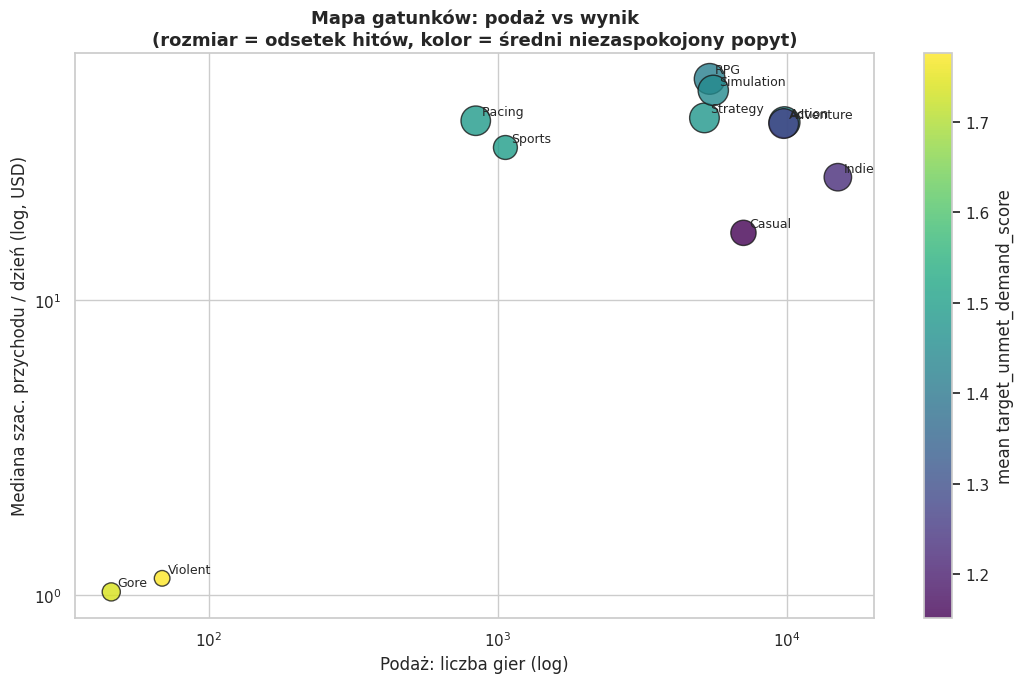

In [34]:
t = genre_tab[genre_tab.median_rev_per_day > 0]
fig, ax = plt.subplots(figsize=(11, 7))
sc = ax.scatter(t.n_games, t.median_rev_per_day, s=40 + t.hit_rate * 1500, c=t.mean_unmet, cmap="viridis", alpha=.8, edgecolor="k")
ax.set_xscale("log"); ax.set_yscale("log")
for g, r in t.nlargest(12, "median_rev_per_day").iterrows():
    ax.annotate(g, (r.n_games, r.median_rev_per_day), fontsize=9, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("Podaż: liczba gier (log)"); ax.set_ylabel("Mediana szac. przychodu / dzień (log, USD)")
ax.set_title("Mapa gatunków: podaż vs wynik\n(rozmiar = odsetek hitów, kolor = średni niezaspokojony popyt)")
plt.colorbar(sc, label="mean target_unmet_demand_score"); plt.tight_layout(); plt.show()

### 12.1 Pary gatunków (węższe nisze)

In [35]:
pr = df[["genres_list"]].copy()
pr["pair"] = pr.genres_list.apply(
    lambda g: [" + ".join(p) for p in combinations(sorted(set(g) - EXCLUDE_GENRES), 2)])
px = pr[["pair"]].explode("pair").dropna().join(df[NICHE_COLS])
pair_tab = niche_table(px, "pair", MIN_N_PAIR)
print(f"Par gatunków z >= {MIN_N_PAIR} grami: {len(pair_tab)}")
display(pair_tab.sort_values("median_rev_per_day", ascending=False).head(20))

Par gatunków z >= 100 grami: 40


,n_games,median_reviews,median_reviews_per_day,median_rev_per_day,total_revenue,median_pos_ratio,median_price,hit_rate,gem_rate,evergreen_rate,mean_unmet,game_share,revenue_share,revenue_to_supply
pair,,,,,,,,,,,,,,
RPG + Simulation,1197,551.000,0.380,71.671,"2,885,257,595.640",0.807,10.990,0.318,0.094,0.142,1.451,0.053,0.049,0.919
Action + RPG,2262,705.000,0.355,69.672,"14,214,169,923.450",0.780,14.990,0.346,0.048,0.167,1.641,0.100,0.239,2.396
Simulation + Strategy,2060,531.000,0.297,69.294,"5,908,628,098.800",0.788,13.990,0.318,0.070,0.180,1.543,0.091,0.099,1.093
Adventure + RPG,2972,520.000,0.299,58.345,"12,267,052,909.020",0.810,11.990,0.306,0.060,0.133,1.411,0.131,0.206,1.574
Racing + Simulation,382,550.500,0.257,57.794,"984,759,650.700",0.795,14.990,0.296,0.052,0.141,1.523,0.017,0.017,0.983
Racing + Sports,346,522.500,0.242,55.589,"881,528,030.040",0.806,14.990,0.240,0.014,0.133,1.406,0.015,0.015,0.971
RPG + Strategy,1605,498.000,0.269,55.397,"3,911,813,064.180",0.789,12.990,0.292,0.050,0.156,1.502,0.071,0.066,0.929
Action + Adventure,4549,530.000,0.278,55.209,"22,719,037,772.970",0.802,11.990,0.321,0.048,0.131,1.477,0.201,0.382,1.904
Adventure + Simulation,1751,486.000,0.294,51.092,"3,983,822,102.400",0.809,9.990,0.297,0.083,0.116,1.411,0.077,0.067,0.867


In [36]:
# Nisze „małe, ale dobre”: poniżej mediany podaży, a powyżej mediany wyniku
cand = pair_tab[(pair_tab.n_games <= pair_tab.n_games.median()) &
                (pair_tab.median_rev_per_day >= pair_tab.median_rev_per_day.median()) &
                (pair_tab.hit_rate >= pair_tab.hit_rate.median())]
print(f"Kandydatów na niszę: {len(cand)}")
display(cand.sort_values("revenue_to_supply", ascending=False).head(20)[
    ["n_games", "median_rev_per_day", "hit_rate", "gem_rate", "mean_unmet", "median_pos_ratio", "median_price", "revenue_to_supply"]])

Kandydatów na niszę: 4


,n_games,median_rev_per_day,hit_rate,gem_rate,mean_unmet,median_pos_ratio,median_price,revenue_to_supply
pair,,,,,,,,
Adventure + Racing,159,40.525,0.277,0.044,1.400,0.812,9.990,1.676
Racing + Simulation,382,57.794,0.296,0.052,1.523,0.795,14.990,0.983
Racing + Sports,346,55.589,0.240,0.014,1.406,0.806,14.990,0.971
RPG + Simulation,1197,71.671,0.318,0.094,1.451,0.807,10.990,0.919


### 12.2 Niezaspokojony popyt

`target_unmet_demand_score` = ln(recenzje+1) · (1 − positive_ratio): wysoki, gdy gra jest popularna, ale gracze są niezadowoleni — sygnał luki jakościowej w segmencie.

,name,primary_genre,release_year,total_reviews,positive_ratio,target_unmet_demand_score
18597,Mirror 2: Project X,Adventure,"2,022.000",116712,0.246,8.796
15802,The Day Before,Action,"2,023.000",23437,0.157,8.479
20547,NBA 2K24,Simulation,"2,023.000",43462,0.312,7.346
12004,Kerbal Space Program 2,Indie,"2,023.000",29384,0.295,7.248
822,Command & Conquer™ 4 Tiberian Twilight,Adventure,"2,010.000",4546,0.167,7.018
8034,NBA 2K18,Simulation,NaN,18792,0.291,6.976
20863,STAR WARS™: Battlefront Classic Collection,Action,"2,024.000",7629,0.229,6.892
1842,Spacebase DF-9,Indie,"2,014.000",4309,0.181,6.854
1133,FlatOut 3: Chaos & Destruction,Racing,"2,011.000",3988,0.180,6.796
16900,Battlefield™ 2042,Action,"2,021.000",297774,0.467,6.713


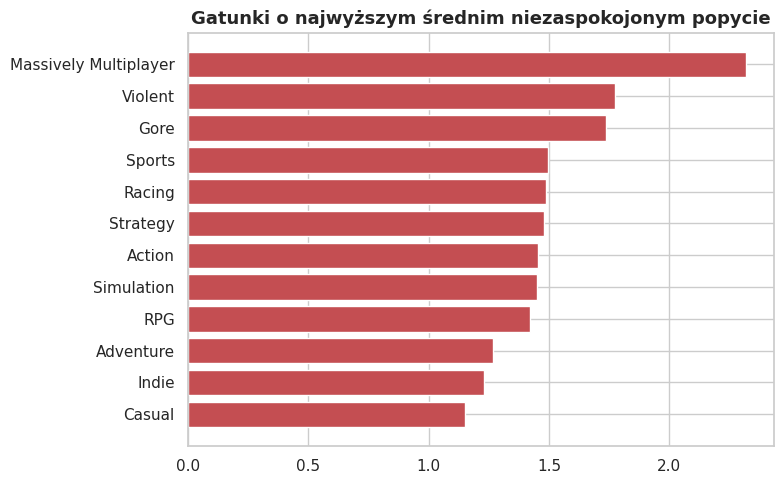

In [37]:
top_unmet = (df[df.total_reviews >= 1000]
             .nlargest(15, "target_unmet_demand_score")
             [["name", "primary_genre", "release_year", "total_reviews", "positive_ratio", "target_unmet_demand_score"]])
display(top_unmet)

g_un = genre_tab.sort_values("mean_unmet", ascending=False).head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(g_un.index, g_un.mean_unmet, color="#C44E52"); ax.set_title("Gatunki o najwyższym średnim niezaspokojonym popycie")
plt.tight_layout(); plt.show()

## 13. Wartości odstające

In [38]:
cols_show = ["name", "primary_genre", "release_year", "price_initial_usd", "total_reviews", "estimated_revenue_usd"]
print("Top 15 wg szacowanego przychodu:"); display(df.nlargest(15, "estimated_revenue_usd")[cols_show])
print("Top 15 wg reviews_per_day:"); display(df.nlargest(15, "reviews_per_day")[cols_show + ["reviews_per_day", "game_age_days"]])
print("Gry z ceną > 100 USD (możliwe błędy / produkty specjalne):")
display(df[df.price_initial_usd > 100][cols_show].sort_values("price_initial_usd", ascending=False).head(15))

Top 15 wg szacowanego przychodu:


,name,primary_genre,release_year,price_initial_usd,total_reviews,estimated_revenue_usd
20611,Black Myth: Wukong,Action,"2,024.000",59.990,1150098,"1,448,881,959.420"
14745,ELDEN RING,Action,"2,022.000",59.990,1056677,"1,331,191,117.830"
13268,Cyberpunk 2077,RPG,"2,020.000",59.990,844921,"1,064,423,026.590"
1989,Rust,Action,"2,018.000",39.990,1227784,"1,031,080,725.360"
13223,Baldur's Gate 3,Adventure,"2,023.000",59.990,760662,"958,274,380.980"
14104,Red Dead Redemption 2,Action,"2,019.000",59.990,733542,"924,108,876.180"
2826,The Witcher 3: Wild Hunt — Remastered,RPG,"2,015.000",49.990,835349,"876,941,026.710"
7674,HELLDIVERS™ 2,Action,"2,024.000",39.990,1017635,"854,599,696.650"
4681,DARK SOULS™ III,Action,"2,016.000",59.990,413775,"521,269,607.250"
1446,DayZ,Action,"2,018.000",49.990,430252,"451,674,247.080"


Top 15 wg reviews_per_day:


,name,primary_genre,release_year,price_initial_usd,total_reviews,estimated_revenue_usd,reviews_per_day,game_age_days
11551,Grand Theft Auto IV: Complete Edition,Action,NaN,NaN,175272,NaN,"175,272.000",1
1768,Assassin’s Creed® IV Black Flag™,Action,NaN,39.990,71071,"59,684,715.090","71,071.000",1
1933,SteamVR,None,NaN,0.000,70640,0.000,"70,640.000",1
695,FINAL FANTASY VII,RPG,NaN,NaN,28011,NaN,"28,011.000",1
1525,Infestation: The New Beginning,Action,NaN,0.000,25418,0.000,"25,418.000",1
903,Sniper Elite V2,Action,NaN,NaN,25221,NaN,"25,221.000",1
637,Total War: SHOGUN 2,None,NaN,NaN,24952,NaN,"24,952.000",1
8034,NBA 2K18,Simulation,NaN,NaN,18792,NaN,"18,792.000",1
1693,Mortal Kombat Komplete Edition,Action,NaN,NaN,18513,NaN,"18,513.000",1
1496,Ace of Spades: Battle Builder,Action,NaN,NaN,18268,NaN,"18,268.000",1


Gry z ceną > 100 USD (możliwe błędy / produkty specjalne):


,name,primary_genre,release_year,price_initial_usd,total_reviews,estimated_revenue_usd


In [39]:
def iqr_share(s):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return ((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).mean() * 100

out_cols = ["log_total_reviews", "log_ccu", "log_price_usd", "positive_ratio", "wilson_score",
            "target_log_revenue_per_day", "target_unmet_demand_score"]
display(pd.Series({c: iqr_share(df[c]) for c in out_cols}, name="% obserwacji poza 1.5*IQR").to_frame())

,% obserwacji poza 1.5*IQR
log_total_reviews,2.454
log_ccu,4.251
log_price_usd,0.000
positive_ratio,2.679
wilson_score,1.986
target_log_revenue_per_day,1.242
target_unmet_demand_score,2.821


## 14. Podsumowanie

In [40]:
n = len(df)
lines = [
    f"Zbiór: {n:,} gier, {N_ORIG_COLS} kolumn oryginalnych; lata premier {int(df.release_year.min())}-{int(df.release_year.max())}.",
    f"Gry darmowe: {df.is_free.astype(float).mean()*100:.1f}% | wycofane/pakietowe: {df.is_delisted_or_bundled.astype(float).mean()*100:.1f}% | indie: {df.is_indie.astype(float).mean()*100:.1f}%.",
    f"Mediana recenzji: {df.total_reviews.median():,.0f}; p90: {df.total_reviews.quantile(.9):,.0f}; p99: {df.total_reviews.quantile(.99):,.0f}.",
    f"Mediana positive_ratio: {df.positive_ratio.median():.3f}.",
    f"Odsetek: hity {df.target_is_commercial_hit.astype(float).mean()*100:.1f}%, ukryte perełki {df.target_is_hidden_gem.astype(float).mean()*100:.2f}%, evergreen {df.target_is_evergreen.astype(float).mean()*100:.1f}%.",
    f"Koncentracja przychodu: Gini = {gini(rev):.3f}; top 1% gier = {rev.iloc[:max(1,int(len(rev)*.01))].sum()/tot*100:.1f}% przychodu.",
    f"Implikowany mnożnik posiadacze/recenzje (mediana): {m.median():.1f} (Boxleiter zakłada 30).",
    f"Braki: metacritic_score {df.metacritic_score.isna().mean()*100:.1f}%, release_date {df.release_date.isna().mean()*100:.1f}%, cena {df.price_initial_usd.isna().mean()*100:.1f}%.",
]
print("\n".join("• " + l for l in lines))

• Zbiór: 22,655 gier, 58 kolumn oryginalnych; lata premier 1997-2026.
• Gry darmowe: 12.6% | wycofane/pakietowe: 5.1% | indie: 66.4%.
• Mediana recenzji: 450; p90: 6,910; p99: 103,466.
• Mediana positive_ratio: 0.824.
• Odsetek: hity 26.6%, ukryte perełki 5.01%, evergreen 11.3%.
• Koncentracja przychodu: Gini = 0.937; top 1% gier = 58.2% przychodu.
• Implikowany mnożnik posiadacze/recenzje (mediana): 95.2 (Boxleiter zakłada 30).
• Braki: metacritic_score 82.4%, release_date 0.3%, cena 5.1%.


### Wnioski i rekomendacje do modelowania

- **Skośność:** używać wersji `log_*` oraz zmiennych celu już zlogarytmizowanych; unikać surowych `total_reviews`, `ccu`, `estimated_revenue_usd` w modelach liniowych.
- **Wyciek danych:** dla każdego targetu wyłączyć jego bezpośrednie wejścia (sekcja 11.2). W szczególności `target_is_commercial_hit` jest wprost zdefiniowany progiem `total_reviews >= 1000`.
- **Czas:** `game_age_days` jest liczone względem daty uruchomienia pipeline'u; do walidacji modeli rozważyć podział czasowy (`release_year`), nie losowy.
- **Braki:** braki w cenie/przychodzie są strukturalne (gry wycofane) — traktować jako osobną kategorię lub wykluczyć z targetów ekonomicznych.
- **Koncentracja przychodów:** ekstremalnie nierówny rozkład → rozważyć metryki rangowe lub modele klasyfikacyjne zamiast regresji na przychodzie.
- **Estymata przychodu:** stały mnożnik 30 jest uproszczeniem (sekcja 9) — wyniki ekonomiczne traktować jako wskaźnik względny, nie absolutny.
- **Nisze:** (uzupełnij: które gatunki/pary wyróżniają się niską podażą i wysokim wynikiem).